# K3: the circuit behind Qwen3-8B's algorithm choice (Kruskal vs Prim)

This notebook is a runnable, annotated version of **`method.py`** from artifact `art_18XvfcJJZi1O` (iteration 8, experiment 41).
It belongs to a study of *why an LLM keeps writing the same "average" solution*, and what actually changes it.
Asked for a minimum-spanning-tree program (task **B3**: *"write `solve(n, roads)` that returns the smallest total cost
to connect all cities"*), **Qwen3-8B** (bf16, thinking off) nearly always opens with the same 61-token preamble. The
next token, at the **decision position DEC**, is ` Kr` (→ Kruskal, the default) or ` Prim` (→ Prim's algorithm, the
minority). The experiment asks **which internal components compute that choice**, and whether editing them changes
the algorithm the model goes on to write.

**Metric:** `m = z(' Kr') - z(' Prim')` at DEC (logit difference, in nats). **Node set:** 36 layers × (32 attention
heads + 1 MLP) × 4 position classes (COND = the condition sentence, SPEC = chat head/task text, OPEN = the opening,
DEC = its last token) = **4,752 nodes**.

| step | stage in `method.py` | what it does |
|---|---|---|
| 1 | `contrasts` | prompt pairs whose only difference shifts `m`: **C1-forced** (*"Implement Prim's algorithm…"* paraphrases vs `' .'` padding twins, the primary contrast after amendment 0a), C1-nat (neutral nouns), C2a (a DFS replication on task T10) |
| 2 | `circuit:X` | attribution-patching (AtP) screen of all 4,752 nodes, a reliability check against exact patching, exact noising/denoising, path patching among the top 15, faithfulness curves |
| 3 | `commit1` | top-10 nodes and **50 write-norm-matched random components** per node frozen in a sha256 hash chain *before* validation |
| 4 | `validate:X` | ABLATE and STEER every top-10 node vs its 50 matched random components; one-sided sign-flip tests, Holm over 20 |
| 5 | `gen:X` | sample whole programs while steering the top-5 nodes (TWIN = unedited, TOP5, RAND5 = matched random five; 30 common-random-number slots), label each by algorithm, exact McNemar TOP5 vs RAND5 |
| 6 | verdict | **PASS / PARTIAL / DISCONFIRMED** by the pre-registered rule |

**What runs here.** Steps 1, 2, 4 and 5 need the 16 GB bf16 model on a ≥ 24 GB GPU. The original run took about
2.4 GPU-hours on an NVIDIA L4. Their code is therefore shown **verbatim and defined, but not called**. Everything that
runs on the CPU after the forward passes is **executed with the original functions**, on the stored outputs of
the GPU stages for the primary contrast **C1forced** (`mini_demo_data.json`). That covers the unit tests, the
amendment-0a decision, AtP reliability, the F4b re-ranking, edges, faithfulness, the matched random pools,
validation statistics, generation statistics, dose sensitivity, the motif comparison with Gemma and the K3 verdict.
At the full-run config (the final values in the config cell) the replay reproduces the stored numbers exactly. The
check tables print `match = True`.

Code copied from the artifact is unchanged except where a line is marked **`# notebook:`**: file reads replaced by
the loaded `data`, inputs that need the tokenizer, and the CLI entry point.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (method.py and its helpers log through it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, statsmodels, matplotlib, torch -- pre-installed on Colab, install locally only (Colab versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

### Helper modules

`method.py` imports its helpers from `src/` (`sys.path.insert(0, .../src)`). The next cells write the parts the CPU
replay needs to `./src`, copied from the artifact:

* `k3cfg.py` (verbatim): paths, model dimensions and the **design constants fixed in commit #0** (seeds, `N_RAND = 50`,
  `KS_FAITH`, `STEER_DOSE = 2.0`, `TE_MIN`, …), plus JSON/hash/logging utilities. `ROOT` resolves to this notebook's folder.
* `k3stats.py` (verbatim): exact sign-flip permutation test, Holm, exact McNemar, Newcombe interval, Spearman/Pearson.
* `k3motif.py` (verbatim): the committed motif function (class shares of the exact noising effect) and its bands.
* `k3circuit.py` (**CPU excerpt**): the 4,752-node set and `select_random`, the matched-random-pool rule. The GPU
  functions of that module (AtP, exact and path patching, write norms, class means, validation edits) and the GPU-only
  modules `k3engine.py` (forward hooks, KV-cache patching, CRN sampling) and `k3prompts.py` (prompts built from the
  iteration-5/7 input files) are not shipped. The verbatim GPU stages below reference them only when called.

In [2]:
from pathlib import Path
Path("src").mkdir(exist_ok=True)   # the helper modules go to ./src, where method.py's sys.path.insert looks for them

In [3]:
%%writefile src/k3cfg.py
#!/usr/bin/env python3
"""K3 constants and utilities: the circuit behind Qwen3-8B's algorithm choice (bf16, thinking off).

Conventions:
- Node = (kind 'head'|'mlp', layer, head (-1 for mlp), position class). Head activation = the head's 128-d slice of
  the o_proj INPUT (z); MLP activation = the output of block.mlp (down_proj output). 36 x (32 + 1) x 4 = 4,752 nodes.
- Position classes per prompt: COND = [p0, p1) (the condition sentence, padding and blank line), SPEC = [0, p0) +
  [p1, P) (chat head, task spec, chat tail incl. the empty think block), OPEN = [P, P + L_open - 1) (the teacher-
  forced canonical opening except its last token), DEC = {P + L_open - 1} (the position whose logits choose the
  decision token).
- Effects follow the plan's sign: clean = default-leaning run (higher metric m), corrupt = minority-leaning run;
  TE = m_clean - m_corrupt > 0; noising effect = m_clean - m_noised; denoising effect = m_denoised - m_corrupt;
  AtP noising estimate = -grad_m(clean) . (a_corrupt - a_clean) (same sign as the noising effect).
- CRN: u_stream(key) = PCG64(stable_seed(key)) uniforms, one per generated token, mapped by the iteration-6 float64
  inverse-CDF sampler (engine5) over the full vocabulary in token-id order.
"""

from __future__ import annotations

import hashlib
import json
import math
import os
import resource
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from loguru import logger

ROOT = Path(__file__).resolve().parents[1]
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
AUDIT_DIR = ROOT / "audit"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR, AUDIT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

I6_SRC = INPUTS / "iter6_exp30" / "src"
E26 = INPUTS / "iter5_exp26"
E35 = INPUTS / "exp35"
E34 = INPUTS / "exp34"
E38 = INPUTS / "exp38"
I6_PROMPTS = INPUTS / "iter6_exp30" / "prompts" / "prompts6.jsonl"
NOUN_BANK = INPUTS / "dep_noun_bank.json"
COMMITS = ROOT / "commitments.log"

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
N_HEADS = 32
HEAD_DIM = 128
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
PRECISION = "bf16"
CLASSES = ("COND", "SPEC", "OPEN", "DEC")
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
U_LEN = 1536

# ------------------------------------------------------------------------------------------------ design (commit #0)
SEED_HELDOUT = 8301
SEED_POOL = 8302
SEED_RAND5 = 8303
SEED_REL = 8304
SEED_CAL = 8305
N_TOP_EXACT = 60
N_CAL = 20
N_REL_PER_CLASS = 40
N_EDGE = 15
N_VAL = 10
N_RAND = 50
KS_FAITH = (5, 10, 15, 30, 60)
STEER_DOSE = 2.0
TE_MIN = 0.2
EDGE_FRAC = 0.05
ATP_SPEARMAN_MIN = 0.6
GEN_SLOTS = tuple(range(6))
GEN_THRESH_PLUS = 6
GEN_PASS_RATIO = 0.8
MAX_NEW_GEN = 1024
GEN_BATCH = 15
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
JUDGE_CAP_USD = 0.30
EXCLUDED_NOUNS = {"tree", "road", "roads", "city", "cities", "bridge", "network", "map", "heap", "graph", "path", "line",
                  "edge", "node", "link", "chain", "street", "key", "cost", "weight", "forest", "ship", "house", "set",
                  "union", "queue", "stack", "list", "number", "point", "table", "train", "plane", "circle", "ring",
                  "web", "net", "wire", "cable", "pipe", "rail", "track", "route", "way", "door", "gate", "wall"}

B3_TOK = {"a": " Kr", "b": " Prim"}          # C1 metric m = z(' Kr') - z(' Prim')
T10_TOK = {"a": " find", "b": " dfs", "b2": " bfs"}  # C2a m = z(' find') - z(' dfs')


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (iteration-7 convention)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def model_path(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snaps = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots"
        if revision and (snaps / revision).exists():
            return str(snaps / revision)
    return model_id


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text}")


def stage_time(stage: str, seconds: float, **extra: Any) -> None:
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": stage, "seconds": round(seconds, 1), "utc": utc_now(),
                                                       **extra}])

Writing src/k3cfg.py


In [4]:
%%writefile src/k3stats.py
#!/usr/bin/env python3
"""Statistics for K3: exact sign-flip permutation test (chunked enumeration up to n = 25, else 10^6 Monte Carlo sign
flips), Holm, exact McNemar, Newcombe (1998, method 10) interval for a paired difference of proportions, Wilson
interval, rule-of-three bound."""

from __future__ import annotations

import math
from typing import Any

import numpy as np
from scipy.stats import binom, norm


def _half_sums(d: np.ndarray) -> np.ndarray:
    n = len(d)
    if n == 0:
        return np.zeros(1)
    idx = np.arange(1 << n, dtype=np.int64)
    signs = ((idx[:, None] >> np.arange(n, dtype=np.int64)[None]) & 1) * 2 - 1
    return signs @ d


def sign_flip_p(d: np.ndarray, n_mc: int = 1_000_000, seed: int = 0, exact_max: int = 40) -> float:
    """One-sided p for mean(d) > 0 under random sign flips: exact enumeration of all 2^n patterns by meet-in-the-middle
    (sums of the two halves, sorted, counted with searchsorted) for n <= exact_max, else n_mc Monte Carlo flips."""
    d = np.asarray(d, dtype=np.float64)
    n = len(d)
    if n == 0:
        return 1.0
    obs = d.sum()
    tol = 1e-9 * max(1.0, float(np.abs(d).sum()))
    if n <= exact_max:
        h = n // 2
        a = _half_sums(d[:h])
        b = np.sort(_half_sums(d[h:]))
        ge = 0
        for c0 in range(0, len(a), 1 << 16):
            ac = a[c0:c0 + (1 << 16)]
            ge += int((len(b) - np.searchsorted(b, obs - ac - tol, side="left")).sum())
        return ge / float(1 << n)
    rng = np.random.default_rng(seed)
    ge = 0
    done = 0
    while done < n_mc:
        m = min(100_000, n_mc - done)
        signs = rng.integers(0, 2, size=(m, n)) * 2 - 1
        ge += int((signs @ d >= obs - tol).sum())
        done += m
    return (ge + 1) / (n_mc + 1)


def holm(ps: list[float]) -> list[float]:
    m = len(ps)
    order = np.argsort(ps)
    adj = np.zeros(m)
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * ps[i])
        adj[i] = min(1.0, run)
    return adj.tolist()


def mcnemar_exact(b: int, c: int, alternative: str = "greater") -> float:
    """b = discordant pairs favouring the first arm, c = favouring the second. One-sided (first > second) or two-sided
    exact binomial p."""
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":
        return float(binom.sf(b - 1, n, 0.5))
    p = 2 * min(binom.cdf(b, n, 0.5), binom.sf(b - 1, n, 0.5))
    return float(min(1.0, p))


def wilson(k: int, n: int, a: float = 0.05) -> tuple[float, float]:
    if n == 0:
        return (0.0, 1.0)
    z = norm.ppf(1 - a / 2)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe_paired(a: int, b: int, c: int, d: int, alpha: float = 0.05) -> dict[str, float]:
    """Newcombe (1998) method 10 for theta = p1 - p2 from paired binary data: a = both 1, b = 1/0, c = 0/1, d = both 0."""
    n = a + b + c + d
    if n == 0:
        return {"diff": 0.0, "lo": -1.0, "hi": 1.0}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n, alpha)
    l2, u2 = wilson(a + c, n, alpha)
    theta = p1 - p2
    num = a * d - b * c
    den = math.sqrt((a + b) * (c + d) * (a + c) * (b + d)) if (a + b) * (c + d) * (a + c) * (b + d) > 0 else 0.0
    if den == 0:
        phi = 0.0
    else:
        phi = (max(num - n / 2, 0) if num > 0 else num) / den
    dl = math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    du = math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return {"diff": theta, "lo": max(-1.0, theta - dl), "hi": min(1.0, theta + du)}


def rule_of_three(n: int) -> float:
    return 3.0 / n if n > 0 else 1.0


def spearman_pearson(a: np.ndarray, b: np.ndarray) -> dict[str, Any]:
    from scipy.stats import pearsonr, spearmanr

    a, b = np.asarray(a).ravel(), np.asarray(b).ravel()
    return {"spearman": float(spearmanr(a, b).statistic), "pearson": float(pearsonr(a, b).statistic),
            "mean_abs_err": float(np.abs(a - b).mean()), "mean_abs_exact": float(np.abs(b).mean()), "n": int(len(a))}

Writing src/k3stats.py


In [5]:
%%writefile src/k3motif.py
#!/usr/bin/env python3
"""Committed motif function (CPU): class shares of |mean noising effect| over the exact-patched node list, validated on
Gemma's g1_pathpatch.json before any Qwen value is computed. Class correspondence Gemma -> Qwen: FORK -> DEC,
CSTAR -> OPEN, SPEC -> SPEC, COND -> COND."""

from __future__ import annotations

from typing import Any

import numpy as np

G2Q = {"FORK": "DEC", "CSTAR": "OPEN", "SPEC": "SPEC", "COND": "COND"}
QCL = ("COND", "SPEC", "OPEN", "DEC")


def motif(exact: list[dict[str, Any]], idx: list[int], signed: bool = False, exclude=None,
          class_map: dict[str, str] | None = None) -> dict[str, float]:
    """exact rows: {'node': 'kind|L|H|CLASS', 'noise_per_pair': [...]}. Share of class c = sum over nodes in c of
    |mean noising effect over pairs idx| / total (signed: signed sums over the signed total)."""
    tot = {c: 0.0 for c in QCL}
    for e in exact:
        kind, L, H, cl = e["node"].split("|")
        cl = (class_map or {}).get(cl, cl)
        if exclude is not None and exclude(kind, int(L[1:]), cl):
            continue
        v = float(np.mean(np.asarray(e["noise_per_pair"], dtype=float)[idx]))
        tot[cl] += v if signed else abs(v)
    s = sum(tot.values()) if signed else sum(abs(x) for x in tot.values())
    s = s if abs(s) > 1e-12 else 1e-12
    out = {c: tot[c] / s for c in QCL}
    out["COND+SPEC"] = out["COND"] + out["SPEC"]
    return out


def dec_stack_depth(exact: list[dict[str, Any]], idx: list[int], top: int, n_layers: int,
                    class_map: dict[str, str] | None = None, dec: str = "DEC") -> dict[str, Any]:
    """DEC-position nodes among the top `top` by |mean effect| with positive mean effect: effect-weighted mean of
    l / (n_layers - 1) and its [min, max]."""
    rows = []
    for e in exact:
        kind, L, H, cl = e["node"].split("|")
        cl = (class_map or {}).get(cl, cl)
        rows.append((abs(float(np.mean(np.asarray(e["noise_per_pair"], dtype=float)[idx]))),
                     float(np.mean(np.asarray(e["noise_per_pair"], dtype=float)[idx])), kind, int(L[1:]), cl))
    rows.sort(key=lambda r: -r[0])
    sel = [r for r in rows[:top] if r[4] == dec and r[1] > 0]
    if not sel:
        return {"n": 0, "depth": None, "min": None, "max": None, "nodes": []}
    w = np.array([r[1] for r in sel])
    d = np.array([r[3] / (n_layers - 1) for r in sel])
    return {"n": len(sel), "depth": float((w * d).sum() / w.sum()), "min": float(d.min()), "max": float(d.max()),
            "nodes": [f"{r[2]}|L{r[3]}|{r[4]}" for r in sel]}


BANDS = {"DEC": (0.38, 0.68), "COND": (0.21, 0.51), "depth": (0.45, 0.80)}


def label(shares: dict[str, float], depth: float | None) -> dict[str, Any]:
    checks = {"DEC_share_in_band": BANDS["DEC"][0] <= shares["DEC"] <= BANDS["DEC"][1],
              "COND_share_in_band": BANDS["COND"][0] <= shares["COND"] <= BANDS["COND"][1],
              "DEC_stack_depth_in_band": depth is not None and BANDS["depth"][0] <= depth <= BANDS["depth"][1]}
    differ = [k for k, v in checks.items() if not v]
    return {"checks": checks, "label": "MOTIF MATCH" if not differ else "DIFFERENT MOTIF", "differs_on": differ}

Writing src/k3motif.py


In [6]:
%%writefile src/k3circuit.py
#!/usr/bin/env python3
"""K3 circuit stages (GPU): attribution screen, exact noising/denoising, path patching among the top 15, faithfulness
curves, write norms and matched random pools, validation rows in the real model. Ported from iteration 7's Gemma G1
(art_HY7uYZz-OjRW src/g1.py: collect, atp_grads, node_vals, make_edit, margins_rows, edge_patching, selection,
class_mean, validation_stats) with Qwen3-8B dimensions, four position classes COND/SPEC/OPEN/DEC and the plan's sign
convention (every effect positive when it carries the clean-minus-corrupt metric difference)."""
# notebook: CPU excerpt of src/k3circuit.py -- the node set (NODES, node_key, KEY2IDX, parse_key) and the matched
# random pools (select_random), verbatim. The GPU parts (node_vals, make_edit, Contrast, collect_all, the AtP / IG-AtP
# screens, exact_effects, edge_patching, head_attention, frozen_rows, write_norms, MeanCache, val_edit) and the module's
# torch / k3engine imports are omitted.
from __future__ import annotations

import time
from typing import Any

import numpy as np
from loguru import logger

from k3cfg import CLASSES, HEAD_DIM, N_HEADS, N_LAYERS

NPL = N_HEADS + 1                      # nodes per layer per class (32 heads + 1 MLP)
NN = len(CLASSES) * N_LAYERS * NPL     # 4,752


# ================================================================================================ nodes
def all_nodes() -> list[tuple[str, int, int, str]]:
    out = []
    for c in CLASSES:
        for l in range(N_LAYERS):
            for h in range(N_HEADS):
                out.append(("head", l, h, c))
            out.append(("mlp", l, -1, c))
    return out


NODES = all_nodes()


def node_key(n: tuple) -> str:
    return f"{n[0]}|L{n[1]}|H{n[2]}|{n[3]}"


KEY2IDX = {node_key(n): i for i, n in enumerate(NODES)}


def parse_key(k: str) -> tuple[str, int, int, str]:
    kind, l, h, c = k.split("|")
    return kind, int(l[1:]), int(h[1:]), c


def select_random(top10: list[int], wn: np.ndarray, seed: int, n_rand: int = 50) -> dict[str, Any]:
    """Matched random components per top node: same type and position class, top-10 excluded. Heads: smallest
    tolerance on +-10% / +-25% / +-50% with >= 50 candidates, 50 drawn without replacement (else the nearest 50).
    MLPs: smallest tolerance on +-10% / +-25% / +-50% / nearest-10 with >= 10 distinct candidates, 50 draws with
    replacement, each draw's patch delta rescaled to the target's write norm."""
    rng = np.random.default_rng(seed)
    tops = set(top10)
    rand_sets: dict[str, list[str]] = {}
    factors: dict[str, list[float]] = {}
    matching: dict[str, Any] = {}
    for j in top10:
        nd = NODES[j]
        k = node_key(nd)
        pool = [i for i in range(NN) if NODES[i][0] == nd[0] and NODES[i][3] == nd[3] and i not in tops]
        w0 = wn[j]
        need = n_rand if nd[0] == "head" else 10
        tol, cand = None, []
        for t in (0.10, 0.25, 0.50):
            cand = [i for i in pool if abs(wn[i] - w0) <= t * max(w0, 1e-12)]
            if len(cand) >= need:
                tol = t
                break
        if tol is None:
            cand = sorted(pool, key=lambda i: abs(wn[i] - w0))[:need]
            tol = f"nearest-{need}"
        if nd[0] == "head":
            pick = rng.choice(len(cand), size=min(n_rand, len(cand)), replace=False)
            draws = [cand[i] for i in pick]
            fac = [1.0] * len(draws)
        else:
            pick = rng.choice(len(cand), size=n_rand, replace=True)
            draws = [cand[i] for i in pick]
            fac = [float(w0 / wn[d]) if wn[d] > 0 else 1.0 for d in draws]
        rand_sets[k] = [node_key(NODES[d]) for d in draws]
        factors[k] = fac
        matching[k] = {"tolerance": tol, "n_candidates": len(cand), "n_distinct_drawn": len(set(draws)),
                       "write_norm": float(w0), "draw_write_norm_mean": float(np.mean([wn[d] for d in draws])),
                       "rescale_factor_mean": float(np.mean(fac)), "rescale_factor_range": [float(min(fac)),
                                                                                           float(max(fac))]}
    return {"rand_sets": rand_sets, "factors": factors, "matching": matching}

Writing src/k3circuit.py


### Imports

The original import block of `method.py`. Only three lines changed: `__file__` does not exist in a notebook, and
the two GPU-only modules are commented out. `from __future__ import annotations` stays in force for every later cell,
so the verbatim GPU functions (annotated with `EN.Metric`, `KC.Contrast`, …) can be defined without those modules.
`setup_logging("method")` is the first line of the original `main()`: loguru then logs to stdout and to
`logs/method.log`.

In [7]:
from __future__ import annotations

import argparse
import gc
import json
import sys
import time
from pathlib import Path
from typing import Any

import numpy as np
import torch
from loguru import logger

sys.path.insert(0, str(Path.cwd() / "src"))  # notebook: no __file__; the helpers were written to ./src above

import k3circuit as KC  # noqa: E402
# import k3engine as EN  # noqa: E402  -- notebook: GPU-only module (hooks, patching, generation), not shipped
# import k3prompts as KP  # noqa: E402  -- notebook: GPU-only module (prompt construction), not shipped
import k3stats as KS  # noqa: E402
from k3cfg import (CACHE_DIR, CLASSES, COMMITS, DATA_DIR, E34, E35, GEN_PASS_RATIO, GEN_SLOTS, GEN_THRESH_PLUS,  # noqa
                   KS_FAITH, MAX_NEW_GEN, N_CAL, N_EDGE, N_LAYERS, N_RAND, N_REL_PER_CLASS, N_TOP_EXACT, N_VAL,
                   PRED_DIR, RESULTS_DIR, ROOT, SEED_CAL, SEED_POOL, SEED_RAND5, SEED_REL, STEER_DOSE, TE_MIN,
                   TEMPLATES, append_jsonl, container_ram_gb, detect_cpus, log_deviation, read_json, read_jsonl,
                   set_ram_limit, setup_logging, sha256_file, sha256_text, stage_time, u_stream, utc_now, write_json)

STATE: dict[str, Any] = {}

# ---- notebook additions: tables, plots, logging
import k3motif as KM
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

setup_logging("method")   # first line of main()

### Data

`mini_demo_data.json` holds the stored outputs of the GPU stages for the primary contrast **C1forced**. Nothing is
rounded. It contains:

* `contrasts`, `gpu_tests`: the outputs of `stage_contrasts` / `stage_gputests` (`results/contrasts.json`, `results/gpu_tests.json`);
* `circuit.C1forced`: per-pair exact noising/denoising effects of the 140 screened + calibration nodes, the 160 random
  reliability nodes (with their AtP and IG-AtP estimates), the 1,171 extra F4b nodes (every DEC node and every MLP),
  all path-patching edges among the top 15, and the per-pair faithfulness curves;
* `write_norms`, `selection`: the 4,752 write norms and the committed matched-random selection (commit #1);
* `validation_rows`: 30 validation prompts × (ABLATE, STEER) × (10 nodes + 2 joint sets) × (node + 50 random draws);
* `datasets[0]`: **the one dataset**, `B3_mst_weight_C1forced_generation`: 60 examples (30 CRN slots × PREFILL/FREE)
  with the algorithm label and test verdict of the TWIN, TOP5 and RAND5 programs;
* `dose_logit`, `gen_dose_rows`: the post-hoc dose sensitivity; `gemma_g1_pathpatch`: Gemma's G1 exact list (motif check);
  `stored_summary`: the full run's statistics, used only to check the replay.

In [8]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-8/experiment-41/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [9]:
data = load_data()
print(data["meta"]["artifact"])
print("model:", data["meta"]["model"], "| contrast:", data["meta"]["contrast"])
print("top-level keys:", list(data))
print(len(data["datasets"][0]["examples"]), "examples in dataset", data["datasets"][0]["dataset"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
art_18XvfcJJZi1O: K3, the circuit behind Qwen3-8B's algorithm choice (iteration 8, experiment 41)
model: Qwen/Qwen3-8B@b968826d (bf16, thinking off) | contrast: C1forced
top-level keys: ['meta', 'contrasts', 'gpu_tests', 'tests_cpu', 'labeller_check', 'gemma_g1_pathpatch', 'circuit', 'write_norms', 'selection', 'validation_rows', 'datasets', 'program_showcase', 'dose_logit', 'gen_dose_rows', 'stored_summary']
60 examples in dataset B3_mst_weight_C1forced_generation


### Config

The replay's tunable parameters. `MAX_PROMPTS` is `stage_validate`'s `--max-prompts`. `N_RAND` and `GEN_SLOTS`
override the `k3cfg` constants the verbatim functions read. They are set to the **full-run values**, because the
whole replay takes about a second. The notebook was tested down to the smallest values in the comments. Shrinking
them shows how much the conclusions depend on sample size: with 8 prompts the smallest one-sided sign-flip p is
1/256, so no node can survive Holm over 20 tests. The GPU-stage design constants are printed for reference only.
They set what the stored data contains and cannot change in a replay.

In [10]:
NAME = "C1forced"            # contrast replayed: the primary C1 contrast after amendment 0a (the only one shipped)
MAX_PROMPTS = None           # validation prompts used by validation_stats: None = all 30 (20 pair + 10 held-out); smallest tested: 2
N_RAND = 50                  # matched random draws per node in the validation null and the RAND5 draw (full run: 50); smallest tested: 2
GEN_SLOTS = tuple(range(6))  # CRN slots per template in the generation / dose statistics (full run: 6); smallest tested: range(1)

# design constants of the GPU stages (k3cfg, fixed in commit #0), shown for reference
print({"N_TOP_EXACT": N_TOP_EXACT, "N_CAL": N_CAL, "N_REL_PER_CLASS": N_REL_PER_CLASS, "N_EDGE": N_EDGE,
       "KS_FAITH": KS_FAITH, "STEER_DOSE": STEER_DOSE, "TE_MIN": TE_MIN, "MAX_NEW_GEN": MAX_NEW_GEN,
       "GEN_THRESH_PLUS": GEN_THRESH_PLUS, "GEN_PASS_RATIO": GEN_PASS_RATIO})

{'N_TOP_EXACT': 60, 'N_CAL': 20, 'N_REL_PER_CLASS': 40, 'N_EDGE': 15, 'KS_FAITH': (5, 10, 15, 30, 60), 'STEER_DOSE': 2.0, 'TE_MIN': 0.2, 'MAX_NEW_GEN': 1024, 'GEN_THRESH_PLUS': 6, 'GEN_PASS_RATIO': 0.8}


## 1. Commits: a sha256 hash chain

Every decision that could be tuned after seeing results is written before the data it governs. That covers the
design (commit #0), the contrast amendment (amend0a), the frozen node and random selection (commit #1) and the
generation spec (commit #2). Each commit is a JSON file under `predictions/` whose sha256 covers the previous
commit's hash, appended to `commitments.log`. `code_hashes()` fingerprints the code. In the notebook only files that
exist are hashed, because `method.py` *is* this notebook.

In [11]:
# ================================================================================================ commits
def commit(name: str, payload: dict[str, Any]) -> dict[str, Any]:
    prev = "0" * 64
    if COMMITS.exists():
        lines = [l for l in COMMITS.read_text().splitlines() if l.strip()]
        if lines:
            prev = lines[-1].split()[2]
    utc = utc_now()
    body = json.dumps({"name": name, "utc": utc, "prev": prev, "payload": payload}, sort_keys=True, default=str)
    h = sha256_text(body)
    write_json(PRED_DIR / f"{name}.json", {"name": name, "utc": utc, "prev": prev, "sha256": h, "payload": payload})
    with open(COMMITS, "a") as fh:
        fh.write(f"{utc} {name} {h} prev={prev}\n")
    logger.info(f"COMMIT {name}: {h[:16]} (prev {prev[:12]})")
    return {"sha256": h, "utc": utc}


def code_hashes() -> dict[str, str]:
    files = sorted((ROOT / "src").glob("*.py")) + [p for p in [ROOT / "method.py"] if p.exists()]  # notebook: method.py is this notebook
    return {str(p.relative_to(ROOT)): sha256_file(p) for p in files}

## 2. Model and decision tokens (GPU, defined only)

`model_tok()` loads Qwen3-8B (bf16, sdpa) through `k3engine.load_model`. `metrics()` builds the logit-difference
metrics for the decision tokens: B3 `' Kr'` vs `' Prim'`, T10 `' find'` vs `' dfs'` (and `' bfs'`). `nouns()` keeps
the neutral nouns that are a single Qwen3 token. The tokenizer and the model are not loaded in this demo.

In [12]:
# ================================================================================================ model / tokens
def model_tok() -> tuple[Any, Any]:
    if "model" not in STATE:
        tok, model, info = EN.load_model()
        STATE.update(model=model, tok=tok, load_info=info)
    return STATE["model"], STATE["tok"]


def tok_only() -> Any:
    if "tok" not in STATE:
        from transformers import AutoTokenizer

        from k3cfg import model_path
        STATE["tok"] = AutoTokenizer.from_pretrained(model_path())
    return STATE["tok"]


def tid(tok: Any, s: str) -> int:
    ids = tok(s, add_special_tokens=False)["input_ids"]
    if len(ids) != 1:
        log_deviation(f"multi_token_{s.strip()}", f"{s!r} is {len(ids)} Qwen3 tokens; the first subword is used")
    return ids[0]


def metrics(tok: Any) -> dict[str, EN.Metric]:
    if "metrics" not in STATE:
        STATE["metrics"] = {"B3": EN.Metric(tid(tok, " Kr"), tid(tok, " Prim")),
                            "T10": EN.Metric(tid(tok, " find"), tid(tok, " dfs")),
                            "T10b": EN.Metric(tid(tok, " find"), tid(tok, " dfs"), tid(tok, " bfs"))}
    return STATE["metrics"]


def nouns(tok: Any) -> list[str]:
    p = RESULTS_DIR / "nouns.json"
    if p.exists():
        return read_json(p)["nouns"]
    ns = [n for n in KP.noun_bank(tok) if n not in ("ass",)]
    write_json(p, {"source": "art_j3Rm_lr2nzR6 concreteness_norms (metadata_noun_bank_candidate == True), single "
                             "Qwen3 token as ' noun' and 'Noun', SUBTLEX order, task-related words excluded",
                   "n": len(ns), "nouns": ns})
    return ns

## 3. Stage `setup`: unit tests and commit #0

`stage_setup()` records the hardware (needs `nvidia-smi`) and asserts that the decision strings are single tokens
(needs the tokenizer). Its CPU half is `cpu_tests()`:

* T2: node keys round-trip;
* T3: the motif function reproduces Gemma's printed shares;
* T4: the exact sign-flip test equals brute force and Monte Carlo;
* T5: Holm and McNemar agree with statsmodels/scipy;
* T6: the matched random pool ladder;
* T7: the labeller check.

T1 (prompt position classes) needs the tokenizer and the prompt files, so its two flags are read from the stored
run. `commit0_payload()` is the **pre-registered design**: every rule and threshold used below.

In [13]:
# ================================================================================================ stage: setup
def stage_setup() -> None:
    t0 = time.time()
    import platform
    import subprocess
    hw = {"gpu": subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used,driver_version",
                                 "--format=csv,noheader"], capture_output=True, text=True).stdout.strip(),
          "cpus": detect_cpus(), "ram_limit_GB": container_ram_gb(), "python": platform.python_version(),
          "torch": torch.__version__, "cuda": torch.version.cuda, "utc": utc_now()}
    import transformers
    hw["transformers"] = transformers.__version__
    write_json(PRED_DIR / "hardware.json", hw)
    tok = tok_only()
    toks = {s: tok(s, add_special_tokens=False)["input_ids"] for s in (" Kr", " Prim", " def", " find", " dfs", " bfs")}
    O = KP.b3_opening()
    pre = KP.t10_prefix()
    asserts = {"single_tokens": {s: len(v) == 1 for s, v in toks.items()}, "token_ids": toks,
               "B3_opening_len": len(O), "B3_opening_text": tok.decode(O),
               "B3_opening_matches_forks_json": tok.decode(O) == read_json(E35 / "results" / "forks.json")["B3"]
               ["opening"]["O_text"],
               "T10_prefix_text": tok.decode(pre), "T10_prefix_ends_in_def": pre[-1] == toks[" def"][0],
               "T10_prefix_len": len(pre)}
    write_json(RESULTS_DIR / "tokenizer_asserts.json", asserts)
    nouns(tok)
    # CPU unit tests
    tests = cpu_tests(tok)
    write_json(RESULTS_DIR / "tests_cpu.json", tests)
    if not COMMITS.exists() or "commit0" not in COMMITS.read_text():
        commit("commit0", commit0_payload())
    stage_time("setup", time.time() - t0)


def cpu_tests(tok: Any) -> dict[str, Any]:
    from k3motif import G2Q, motif
    out: dict[str, Any] = {}
    # T1 positions: disjoint and covering
    # ok = True
    # for w, r in KP.b3_twins(tok).items():
    #     allp = sorted(sum(r["pos"].values(), []))
    #     ok &= allp == list(range(r["P"] + r["L_open"]))
    # for w, r in KP.t10_twins(tok).items():
    #     allp = sorted(sum(r["pos"].values(), []))
    #     ok &= allp == list(range(r["P"] + r["L_open"]))
    # pj = read_json(ROOT / "inputs" / "iter5_exp26" / "units" / "B3" / "positions.json")
    # ok_pos = all(KP.b3_twins(tok)[w]["P"] == pj[w]["P"] and KP.b3_twins(tok)[w]["p1"] == pj[w]["p1"] for w in TEMPLATES)
    # out["T1_classes_disjoint_covering"] = bool(ok)
    # out["T1_positions_match_positions_json"] = bool(ok_pos)
    # notebook: T1 needs the Qwen3 tokenizer and the prompt files under inputs/ (not shipped with the demo); its two
    # flags are taken from the full run's results/tests_cpu.json
    out["T1_classes_disjoint_covering"] = data["tests_cpu"]["T1_classes_disjoint_covering"]
    out["T1_positions_match_positions_json"] = data["tests_cpu"]["T1_positions_match_positions_json"]
    # T2 node keys
    out["T2_n_nodes"] = len(KC.NODES)
    out["T2_roundtrip"] = all(KC.parse_key(KC.node_key(n)) == n for n in KC.NODES)
    # T3 motif on Gemma
    g = data["gemma_g1_pathpatch"]  # notebook: was read_json(ROOT / "inputs" / "exp38" / "results" / "g1_pathpatch.json")
    sh = motif(g["exact"], list(range(15)), class_map=G2Q)
    out["T3_gemma_motif"] = {k: round(v, 4) for k, v in sh.items()}
    out["T3_pass"] = abs(sh["DEC"] - 0.53) <= 0.02 and abs(sh["COND"] - 0.36) <= 0.02
    # T4 sign flip
    rng = np.random.default_rng(1)
    d = rng.normal(0.3, 1, 10)
    brute = np.mean([np.dot(np.array([1 if (k >> i) & 1 else -1 for i in range(10)]), d) >= d.sum() - 1e-12
                     for k in range(1 << 10)])
    out["T4_exact_vs_brute"] = abs(KS.sign_flip_p(d) - brute) < 1e-12
    d22 = rng.normal(0.2, 1, 22)
    out["T4_exact_vs_mc"] = abs(KS.sign_flip_p(d22) - KS.sign_flip_p(d22, exact_max=0)) < 0.002
    # T5 Holm / McNemar vs statsmodels / scipy
    from statsmodels.stats.multitest import multipletests
    ps = [0.01, 0.04, 0.03, 0.2, 0.001]
    out["T5_holm"] = bool(np.allclose(KS.holm(ps), multipletests(ps, method="holm")[1]))
    from scipy.stats import binomtest
    out["T5_mcnemar"] = abs(KS.mcnemar_exact(8, 0) - binomtest(8, 8, 0.5, alternative="greater").pvalue) < 1e-12
    out["T5_mcnemar_7_1"] = round(KS.mcnemar_exact(7, 1, "two-sided"), 4)
    # T6 random pool ladder on synthetic norms
    wn = np.abs(rng.normal(1, 0.3, KC.NN))
    top = [5, 40, 1188 * 3 + 32]
    sel = KC.select_random(top, wn, 0)
    out["T6_pool"] = {k: (len(v), sel["matching"][k]["tolerance"]) for k, v in sel["rand_sets"].items()}
    out["T6_pass"] = all(len(v) == 50 for v in sel["rand_sets"].values())
    lab = RESULTS_DIR / "labeller_check.json"
    out["T7_labeller"] = data["labeller_check"]["summary"]  # notebook: was read_json(lab)["summary"] if lab.exists() else None
    out["all_pass"] = bool(out["T1_classes_disjoint_covering"] and out["T2_n_nodes"] == 4752 and out["T2_roundtrip"]
                           and out["T3_pass"] and out["T4_exact_vs_brute"] and out["T4_exact_vs_mc"] and
                           out["T5_holm"] and out["T5_mcnemar"] and out["T6_pass"])
    logger.info(f"CPU tests: {out}")
    return out


def commit0_payload() -> dict[str, Any]:
    return {
        "claim": "K3: components that compute the odds of the decision token, validated in the real model",
        "model": "Qwen/Qwen3-8B@b968826d (bf16, thinking off, sdpa)",
        "node_set": "36 x 32 heads (o_proj input slice) + 36 MLP outputs at COND / SPEC / OPEN / DEC = 4,752 nodes",
        "metrics": {"C1": "m = z(' Kr') - z(' Prim') at DEC (last of B3's 61-token opening)",
                    "C2a": "m = z(' find') - z(' dfs') at DEC (' def', token 10 of the T10 prefix)",
                    "C2b": "m' = z(' find') - logsumexp(z(' dfs'), z(' bfs'))"},
        "pair_rule": "C1-nat: 24 neutral-noun variants per template W1-W5; within template the k-th highest m (clean) "
                     "with the k-th lowest (corrupt): set A k = 1..3, set B k = 4..6; held-out H 2 per template "
                     "(seed 8301, one above and one below the template median); pairs with TE <= 0.2 dropped; < 10 "
                     "surviving pairs or mean TE(A) < 1.0 nat -> F2 (C1-forced primary)",
        "screen": "AtP noising (grad at clean x (corrupt - clean)); top 60 by |mean AtP|; reliability: exact noising of "
                  "40 random nodes per class (seed 8304); Spearman < 0.6 -> IG-AtP (5 alphas) and 120 exact nodes",
        "exact": "noising and denoising of the top 60 + 20 random calibration nodes (seed 8305); ranking by |mean "
                 "noising effect| (Gemma's rule)",
        "edges": "path patching among the top 15; keep |mean| >= 0.05 x mean TE",
        "faithfulness": "k in {5,10,15,30,60}: clean input, non-circuit nodes frozen to corrupt values (type 1) or to "
                        "the corrupt-class same-template mean (type 2), circuit nodes live; completeness (top-k "
                        "noised) and sufficiency (top-k denoised)",
        "random_matching": "heads: +-10/25/50% write norm (>= 50 candidates), 50 without replacement; MLPs: "
                           "+-10/25/50%/nearest-10 (>= 10 distinct), 50 with replacement, delta rescaled to the "
                           "target's write norm; seed 8302",
        "validation": "ABLATE node <- opposite-class mean; STEER node <- own + 2 x (opposite mean - own mean); oriented "
                      "dm vs in-chunk base; d_i = dm_node - mean dm_rand; one-sided sign-flip (exact n <= 25 else "
                      "1e6 MC); PRIMARY Holm over all 20 node x test p; NODE PASS = Holm p < 0.05 in both tests; "
                      "Gemma's within-test Holm reported beside",
        "time_rule": "if the first-prompt timing extrapolates validation of one contrast beyond 45 min, V = 15 clean + "
                     "10 H; beyond that H drops to 5; random count never reduced (C1-nat)",
        "generation": "arms TWIN, TOP5 (STEER toward the minority on all five), RAND5 (frozen matched five, seed 8303); "
                      "N = 30 = W1-W5 x 6 CRN slots; T 1, top-p 1, no top-k, max_new 1024; PRIMARY = PREFILL "
                      "(prompt + opening prefilled for every arm); SECONDARY = FREE (OPEN/DEC edits fire only while "
                      "the generated prefix equals the opening); targets B3 correct prim_heap/prim_array, T10 correct "
                      "dfs",
        "gen_criteria": "TOP5 - TWIN correct-target >= 6; exact McNemar TOP5 vs RAND5 p < 0.05; pass(TOP5) >= 0.8 x "
                        "pass(TWIN)",
        "K3_verdict": "PASS = C1: >= 5 of 10 nodes pass both tests AND PREFILL top-5 meets all three generation "
                      "criteria; PARTIAL = exactly one; DISCONFIRMED = no top-10 node passes either test; C2a "
                      "reported with the same rule; the C1 McNemar p enters the paper's primary Holm family",
        "predictions": {"P1": ">= 5 of 10 nodes pass both tests on C1-nat",
                        "P2": "PREFILL top-5 steering: TWIN + >= 6 correct Prim of 30, beats RAND5 (McNemar p < "
                              "0.05), pass >= 0.8 x twin",
                        "P3": "the same on C2a toward DFS",
                        "P4": "motif: DEC share in [0.38, 0.68], COND share in [0.21, 0.51], DEC-position stack "
                              "effect-weighted depth in [0.45, 0.80]",
                        "P5": "top-10 Jaccard between pair sets A and B >= 0.4"},
        "motif_function": "share(c) = sum over the exact list (top 40 by |AtP| + 20 random calibration nodes, Gemma's "
                          "composition) in class c of |mean noising effect| / total; validated on Gemma's "
                          "g1_pathpatch.json (FORK 0.531, COND 0.357) before any Qwen value",
        "drop_order": ["transcoder extension", "C2b", "pair set B", "held-out beyond 5", "FREE condition rows"],
        "never_drop": ["C1 screen + exact + path patching + matched-random validation + PREFILL top-5 generation",
                       "C2a with validation", "motif test", "novelty audit"],
        "code_sha256": code_hashes(),
    }

**Run the CPU half of `stage_setup()`.** These are the unit tests and the contrast-free commit #0. The printed design
is what the rest of the notebook is held to.

In [14]:
tests = cpu_tests(None)                       # tok=None: the T1 flags come from the stored run (see cpu_tests)
write_json(RESULTS_DIR / "tests_cpu.json", tests)
if not COMMITS.exists() or "commit0" not in COMMITS.read_text():
    commit("commit0", commit0_payload())
print("CPU tests all pass:", tests["all_pass"], "| Gemma motif (T3):", tests["T3_gemma_motif"])
c0 = read_json(PRED_DIR / "commit0.json")["payload"]
for k in ("claim", "node_set", "metrics", "pair_rule", "screen", "validation", "generation", "gen_criteria", "K3_verdict"):
    print(f"- {k}: {c0[k]}")

10:52:07|INFO   |CPU tests: {'T1_classes_disjoint_covering': True, 'T1_positions_match_positions_json': True, 'T2_n_nodes': 4752, 'T2_roundtrip': True, 'T3_gemma_motif': {'COND': 0.3574, 'SPEC': 0.0592, 'OPEN': 0.0522, 'DEC': 0.5313, 'COND+SPEC': 0.4166}, 'T3_pass': True, 'T4_exact_vs_brute': np.True_, 'T4_exact_vs_mc': True, 'T5_holm': True, 'T5_mcnemar': np.True_, 'T5_mcnemar_7_1': 0.0703, 'T6_pool': {'head|L0|H5|COND': (50, 0.25), 'head|L1|H7|COND': (50, 0.1), 'mlp|L0|H-1|DEC': (50, 0.25)}, 'T6_pass': True, 'T7_labeller': {'ref|B3': {'n': 4, 'agree': 4, 'passed': 4}, 'ref|T10': {'n': 4, 'agree': 4, 'passed': 4}, 'gold|T10': {'n': 22, 'agree': 22, 'passed': 22}, 'tw|B3': {'n': 30, 'agree': 30, 'passed': 28}}, 'all_pass': True}


10:52:07|INFO   |COMMIT commit0: 00a750c02b1184c3 (prev 000000000000)


CPU tests all pass: True | Gemma motif (T3): {'COND': 0.3574, 'SPEC': 0.0592, 'OPEN': 0.0522, 'DEC': 0.5313, 'COND+SPEC': 0.4166}
- claim: K3: components that compute the odds of the decision token, validated in the real model
- node_set: 36 x 32 heads (o_proj input slice) + 36 MLP outputs at COND / SPEC / OPEN / DEC = 4,752 nodes
- metrics: {'C1': "m = z(' Kr') - z(' Prim') at DEC (last of B3's 61-token opening)", 'C2a': "m = z(' find') - z(' dfs') at DEC (' def', token 10 of the T10 prefix)", 'C2b': "m' = z(' find') - logsumexp(z(' dfs'), z(' bfs'))"}
- pair_rule: C1-nat: 24 neutral-noun variants per template W1-W5; within template the k-th highest m (clean) with the k-th lowest (corrupt): set A k = 1..3, set B k = 4..6; held-out H 2 per template (seed 8301, one above and one below the template median); pairs with TE <= 0.2 dropped; < 10 surviving pairs or mean TE(A) < 1.0 nat -> F2 (C1-forced primary)
- screen: AtP noising (grad at clean x (corrupt - clean)); top 60 by |mean AtP|; r

## 4. Stage `contrasts` (GPU, defined only)

* **C1-nat** teacher-forces the 61-token opening after 120 noun variants (*"Do not use `<noun>` for this task."*,
  24 per template W1-W5) and pairs, within each template, the k-th highest `m` with the k-th lowest (set A: k = 1-3).
* **C1-forced** pairs 10 forced-Prim paraphrases (corrupt) with their `' .'` padding twins (clean); F11-F15 are held out.
* **C2a** replaces the T10 spec states with those of a forced-DFS prompt (the F3 ladder of exchange bands).
`surviving_pairs()` drops pairs with total effect `TE = m_clean - m_corrupt <= TE_MIN`.

In [15]:
# ================================================================================================ contrasts
def build_c1nat(tok: Any, model: Any) -> dict[str, Any]:
    """Teacher-force the opening on 120 variants (batched per template) -> m_v; pairs A/B; held-out."""
    p = RESULTS_DIR / "c1nat_variants.json"
    O = KP.b3_opening()
    met = metrics(tok)["B3"]
    if "b3_variants" not in STATE:
        STATE["b3_variants"] = KP.b3_variants(tok, nouns(tok), 24)
    vs = STATE["b3_variants"]
    if p.exists():
        mv = read_json(p)["m"]
    else:
        mv = {}
        for w in TEMPLATES:
            ws = [v for v in vs if v["template"] == w]
            for b0 in range(0, len(ws), 12):
                part = ws[b0:b0 + 12]
                inp = torch.tensor([v["ids"] + O for v in part], device="cuda")
                with torch.no_grad():
                    o = model.model(input_ids=inp, use_cache=False)
                    mm = met(o.last_hidden_state[:, -1])
                for v, m in zip(part, mm.tolist()):
                    mv[v["vid"]] = m
                del o, mm
        sd = {w: float(np.std([mv[v["vid"]] for v in vs if v["template"] == w])) for w in TEMPLATES}
        write_json(p, {"m": mv, "sd_by_template": sd, "sd_all": float(np.std(list(mv.values()))),
                       "note": "batched teacher-forced m (12 per batch), used only to rank and pair variants"})
    A = KP.pair_by_rank(vs, mv, (1, 2, 3))
    B = KP.pair_by_rank(vs, mv, (4, 5, 6))
    used = {a for ab in A + B for a in ab}
    H = KP.heldout(vs, mv, used)
    byv = {v["vid"]: v for v in vs}
    return {"variants": byv, "m": mv, "A": A, "B": B, "H": H}


def make_c1(tok: Any, model: Any, which: str = "A") -> KC.Contrast:
    info = build_c1nat(tok, model)
    byv = info["variants"]
    prompts, pairs = [], []
    for c, x in info[which]:
        prompts += [dict(byv[c], cls="clean"), dict(byv[x], cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    for vid, side in info["H"]:
        prompts.append(dict(byv[vid], cls=side, heldout=True))
    C = KC.Contrast("C1nat" if which == "A" else "C1natB", metrics(tok)["B3"], prompts, KP.b3_opening(), pairs)
    return C


def forced_list(tok: Any) -> list:
    if "forced" not in STATE:
        STATE["forced"] = KP.b3_forced(tok)
    return STATE["forced"]


def make_c1forced(tok: Any) -> KC.Contrast:
    """Amendment 0a: 10 forced-Prim paraphrases (F1-F10) against their padding twins; F11-F15 and their padding twins
    are the 10 held-out validation prompts."""
    prompts, pairs = [], []
    fl = forced_list(tok)
    for pad, f in fl[:10]:
        prompts += [dict(pad, cls="clean"), dict(f, cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    for pad, f in fl[10:15]:
        prompts += [dict(pad, cls="clean", heldout=True), dict(f, cls="corrupt", heldout=True)]
    return KC.Contrast("C1forced", metrics(tok)["B3"], prompts, KP.b3_opening(), pairs)


def make_c1mix(tok: Any, model: Any) -> KC.Contrast:
    info = build_c1nat(tok, model)
    byv = info["variants"]
    prompts, pairs = [], []
    k12 = [ab for i, ab in enumerate(info["A"]) if i % 3 in (0, 1)]          # k = 1, 2 of each template
    for c, x in k12:
        prompts += [dict(byv[c], cls="clean"), dict(byv[x], cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    for pad, f in forced_list(tok)[:5]:
        prompts += [dict(pad, cls="clean"), dict(f, cls="corrupt")]
        pairs.append((len(prompts) - 2, len(prompts) - 1))
    return KC.Contrast("C1mix", metrics(tok)["B3"], prompts, KP.b3_opening(), pairs)


@torch.no_grad()
def exchange_source(model: Any, tok: Any, blocks: list[int]) -> dict[str, Any]:
    """Block outputs of the forced-DFS prompt (+ T10 prefix) at its task-spec positions [p1, spec_end)."""
    if "xsrc" in STATE and STATE["xsrc"]["blocks"] == blocks:
        return STATE["xsrc"]
    f = KP.t10_forced_dfs(tok)
    ids = f["ids"] + KP.t10_prefix()
    caps: dict[int, torch.Tensor] = {}
    sp = list(range(f["p1"], f["spec_end"]))
    cap = {("resid", l): (lambda x, l=l: caps.__setitem__(l, x[0, sp].detach().clone())) for l in blocks}
    with EN.edit_hooks(model, [], cap):
        model.model(input_ids=torch.tensor([ids], device="cuda"), use_cache=False)
    STATE["xsrc"] = {"blocks": blocks, "states": caps, "forced": f}
    return STATE["xsrc"]


def exchange_edits(rec: dict[str, Any], src: dict[str, Any], alpha: float = 1.0,
                   clean_states: dict[int, torch.Tensor] | None = None) -> list[EN.Edit]:
    sp = list(range(rec["p1"], rec["spec_end"]))
    out = []
    for l in src["blocks"]:
        v = src["states"][l]
        assert v.shape[0] == len(sp), "spec spans differ"
        if alpha != 1.0 and clean_states is not None:
            v = clean_states[l] + alpha * (v - clean_states[l])
        out.append(EN.Edit("resid", l, sp, EN.const_fn(v), name=f"exch_L{l}"))
    return out


def make_c2a(tok: Any, model: Any, blocks: list[int]) -> KC.Contrast:
    ns = [n for n in nouns(tok)]
    t_nouns = ["ship"] + ns[:2]
    h_nouns = ns[2:4]
    if "t10_variants" not in STATE:
        STATE["t10_variants"] = (KP.t10_variants(tok, t_nouns), KP.t10_variants(tok, h_nouns))
    tv, hv = STATE["t10_variants"]
    src = exchange_source(model, tok, blocks)
    prompts, pairs, base = [], [], {}
    for v in tv:
        prompts.append(dict(v, cls="clean"))
        prompts.append(dict(v, cls="corrupt", exchanged=True, vid=v["vid"] + "|exch"))
        i = len(prompts) - 1
        base[i] = (lambda rec=prompts[i]: exchange_edits(rec, src))
        pairs.append((i - 1, i))
    for v in hv:
        prompts.append(dict(v, cls="clean", heldout=True))
    C = KC.Contrast("C2a", metrics(tok)["T10"], prompts, KP.t10_prefix(), pairs, base=base)
    C.exchange_blocks = blocks
    return C


def stage_contrasts() -> None:
    t0 = time.time()
    model, tok = model_tok()
    out: dict[str, Any] = {}
    info = build_c1nat(tok, model)
    out["C1nat_sd_m_v"] = read_json(RESULTS_DIR / "c1nat_variants.json")["sd_all"]
    for which in ("A", "B"):
        C = make_c1(tok, model, which)
        rows = []
        for (c, x) in C.pairs:
            a_c = EN.collect(model, C.run_ids(c), C.metric)
            a_x = EN.collect(model, C.run_ids(x), C.metric)
            rows.append({"clean": C.prompts[c]["vid"], "corrupt": C.prompts[x]["vid"], "m_clean": a_c.m,
                         "m_corrupt": a_x.m, "TE": a_c.m - a_x.m, "p_kr_clean": a_c.p_a, "p_prim_clean": a_c.p_b,
                         "p_kr_corrupt": a_x.p_a, "p_prim_corrupt": a_x.p_b})
            del a_c, a_x
        te = [r["TE"] for r in rows]
        out[f"C1nat_{which}"] = {"pairs": rows, "TE_mean": float(np.mean(te)), "TE_sd": float(np.std(te)),
                                 "n_TE_gt_min": int(sum(t > TE_MIN for t in te))}
        logger.info(f"C1nat {which}: TE mean {np.mean(te):.3f} (sd {np.std(te):.3f}); {sum(t > TE_MIN for t in te)}"
                    f"/15 > {TE_MIN}")
    out["C1nat_heldout"] = info["H"]
    C = make_c1forced(tok)
    rows = []
    for (c, x) in C.pairs:
        a_c = EN.collect(model, C.run_ids(c), C.metric)
        a_x = EN.collect(model, C.run_ids(x), C.metric)
        rows.append({"clean": C.prompts[c]["vid"], "corrupt": C.prompts[x]["vid"], "m_clean": a_c.m,
                     "m_corrupt": a_x.m, "TE": a_c.m - a_x.m, "p_prim_corrupt": a_x.p_b})
    out["C1forced"] = {"pairs": rows, "TE_mean": float(np.mean([r["TE"] for r in rows]))}
    # C2a with the F3 fallback ladder
    chosen = None
    tries = []
    for blocks, tag in ((list(range(36)), "X_0-35"), (list(range(12, 24)), "X_12-23"), ([16], "X_16")):
        C2 = make_c2a(tok, model, blocks)
        rows = []
        for (c, x) in C2.pairs:
            a_c = EN.collect(model, C2.run_ids(c), C2.metric)
            a_x = EN.collect(model, C2.run_ids(x), C2.metric, C2.base(x))
            rows.append({"clean": C2.prompts[c]["vid"], "m_clean": a_c.m, "m_corrupt": a_x.m, "TE": a_c.m - a_x.m,
                         "argmax_corrupt": tok.decode([a_x.top[0][0]]), "argmax_clean": tok.decode([a_c.top[0][0]]),
                         "p_dfs_corrupt": a_x.p_b, "p_find_clean": a_c.p_a})
        te = float(np.mean([r["TE"] for r in rows]))
        flips = float(np.mean([r["argmax_corrupt"] == " dfs" for r in rows]))
        tries.append({"config": tag, "TE_mean": te, "frac_argmax_dfs": flips, "pairs": rows})
        logger.info(f"C2a {tag}: TE mean {te:.2f}, argmax dfs {flips:.2f}")
        C2.clear_base()
        if flips >= 0.5 and te >= 5.0:
            chosen = tag
            break
    out["C2a_tries"] = tries
    out["C2a_config"] = chosen
    if chosen is None:
        log_deviation("F3_C2c", "no exchange configuration flipped the T10 argmax to ' dfs' with a >= 5 nat shift; "
                      "C2a falls back to the input contrast C2c is NOT built in this run (see C2a_tries)", "major")
    elif chosen != "X_0-35":
        log_deviation("F3_exchange_band", f"C2a uses exchange configuration {chosen} (X_0-35 failed the check)")
    write_json(RESULTS_DIR / "contrasts.json", out)
    stage_time("contrasts", time.time() - t0)


def c2a_blocks() -> list[int]:
    cfg = read_json(RESULTS_DIR / "contrasts.json")["C2a_config"] or "X_0-35"
    return {"X_0-35": list(range(36)), "X_12-23": list(range(12, 24)), "X_16": [16]}[cfg]


def get_contrast(name: str) -> KC.Contrast:
    model, tok = model_tok()
    if name == "C1nat":
        return make_c1(tok, model, "A")
    if name == "C1natB":
        return make_c1(tok, model, "B")
    if name == "C1forced":
        return make_c1forced(tok)
    if name == "C1mix":
        return make_c1mix(tok, model)
    if name == "C2a":
        return make_c2a(tok, model, c2a_blocks())
    raise ValueError(name)


def surviving_pairs(C: KC.Contrast, acts: dict[int, EN.Acts]) -> list[tuple[int, int]]:
    keep = []
    for c, x in C.pairs:
        te = acts[c].m - acts[x].m
        if te > TE_MIN:
            keep.append((c, x))
        else:
            log_deviation(f"{C.name}_pair_dropped_{C.prompts[c]['vid']}",
                          f"{C.name}: pair {C.prompts[c]['vid']} vs {C.prompts[x]['vid']} has TE {te:.3f} <= {TE_MIN}")
    return keep

**What `stage_contrasts()` produced** (`results/contrasts.json`). The aggregation lines are re-run on the stored
pairs. The natural contrast is weak (TE ≈ 0.9 nat). The forced paraphrases move `m` by ≈ 10 nats, turning a 72 %
Kruskal decision into a near-certain Prim one.

In [16]:
out = data["contrasts"]
for which in ("A", "B"):
    rows = out[f"C1nat_{which}"]["pairs"]
    te = [r["TE"] for r in rows]
    print(f"C1nat {which}: TE mean {np.mean(te):.3f} (sd {np.std(te):.3f}); {sum(t > TE_MIN for t in te)}"
          f"/15 > {TE_MIN}")
print("C1nat sd of m over the 120 variants:", round(out["C1nat_sd_m_v"], 3))
display(pd.DataFrame(out["C1nat_A"]["pairs"]).head(5).round(3))
print(f"C1forced: TE mean {out['C1forced']['TE_mean']:.2f} nats over {len(out['C1forced']['pairs'])} pairs")
display(pd.DataFrame(out["C1forced"]["pairs"]).round(3))
print("C2a exchange ladder:", [(t["config"], round(t["TE_mean"], 2), t["frac_argmax_dfs"]) for t in out["C2a_tries"]],
      "-> chosen", out["C2a_config"])

C1nat A: TE mean 0.893 (sd 0.377); 15/15 > 0.2
C1nat B: TE mean 0.393 (sd 0.186); 12/15 > 0.2
C1nat sd of m over the 120 variants: 0.338


,clean,corrupt,m_clean,m_corrupt,TE,p_kr_clean,p_prim_clean,p_kr_corrupt,p_prim_corrupt
0,W1|guy,W1|mother,1.230,0.606,0.624,0.769,0.220,0.615,0.373
1,W1|phone,W1|kid,1.230,0.833,0.398,0.772,0.221,0.670,0.317
2,W1|office,W1|baby,1.038,0.728,0.311,0.724,0.266,0.671,0.317
3,W2|coffee,W2|head,1.223,-0.106,1.329,0.773,0.221,0.430,0.552
4,W2|car,W2|school,1.439,0.270,1.169,0.813,0.181,0.553,0.431


C1forced: TE mean 9.91 nats over 10 pairs


,clean,corrupt,m_clean,m_corrupt,TE,p_prim_corrupt
0,F1|forced|pad,F1|forced,1.241,-8.600,9.841,0.355
1,F2|forced|pad,F2|forced,1.164,-9.342,10.506,0.975
2,F3|forced|pad,F3|forced,1.139,-5.882,7.021,0.985
3,F4|forced|pad,F4|forced,1.179,-9.246,10.425,0.981
4,F5|forced|pad,F5|forced,1.164,-10.837,12.001,0.992
5,F6|forced|pad,F6|forced,1.179,-9.306,10.485,0.987
6,F7|forced|pad,F7|forced,1.179,-5.872,7.051,0.967
7,F8|forced|pad,F8|forced,1.241,-10.178,11.420,0.997
8,F9|forced|pad,F9|forced,1.249,-8.663,9.911,0.990
9,F10|forced|pad,F10|forced,1.241,-9.162,10.403,0.892


C2a exchange ladder: [('X_0-35', 19.33, 1.0)] -> chosen X_0-35


## 5. Amendment 0a: which C1 contrast is primary

Commit #0 fixed rule **F2**: if C1-nat set A has mean TE < 1.0 nat or fewer than 10 pairs with TE > 0.2, C1-forced
becomes the primary C1 contrast. Rule **F5** keeps the faster suffix forwards (prefix KV reused) only if they deviate
from full recomputation by no more than the bf16 batch-shape noise floor measured in GPU test U3b. `stage_amend0a()`
evaluates both rules on the stored contrast and GPU-test files and commits the outcome.

In [17]:
# ================================================================================================ amendment 0a
def stage_amend0a() -> None:
    c = data["contrasts"]  # notebook: was read_json(RESULTS_DIR / "contrasts.json")
    g = data["gpu_tests"]  # notebook: was read_json(RESULTS_DIR / "gpu_tests.json")
    te_a = c["C1nat_A"]["TE_mean"]
    f2 = te_a < 1.0 or c["C1nat_A"]["n_TE_gt_min"] < 10
    u3, u3b = g["U3"], g.get("U3b_full_vs_full", {})
    use_suffix = u3["mean_abs_diff"] <= max(0.05, 1.5 * u3b.get("mean_abs_diff", 0.0) + 0.02)
    payload = {
        "F2_triggered": f2, "C1nat_A_TE_mean": te_a, "C1nat_A_n_TE_gt_0.2": c["C1nat_A"]["n_TE_gt_min"],
        "C1_primary": "C1forced" if f2 else "C1nat",
        "C1forced_design": "10 forced-Prim paraphrases F1-F10 (corrupt) vs their ' .' padding twins (clean) as pairs; "
                           "F11-F15 and their padding twins as the 10 held-out validation prompts (no Prim paraphrase "
                           "set exists in art_MZAfDPVhM6Ui beyond its single wording, so the 15 wordings are written "
                           "here); C1-nat is still screened and reported descriptively; C1mix uses F1-F5",
        "C1forced_TE": [r["TE"] for r in c["C1forced"]["pairs"]],
        "metric_readout": "m read in fp32 from the bf16 final-norm hidden state (h . (W_a - W_b)); the bf16 lm_head "
                          "output is quantised to 0.125-0.25 nats",
        "F5_decision": {"suffix_vs_full": u3, "full_vs_full_batch_shapes": u3b, "keep_suffix_forwards": use_suffix,
                        "rule": "suffix forwards are kept when their mean deviation from full recompute is no larger "
                                "than 1.5 x the full-vs-full batch-shape noise + 0.02 nats (both are bf16 path noise "
                                "and cancel within each in-chunk base-row comparison); otherwise every row is a full "
                                "forward"},
        "generation_alignment_rule": "TOP5 for generation = the five highest-ranked top-10 nodes whose position class "
                                     "aligns with the B3 twin prompt; COND nodes of C1forced (the forced instruction "
                                     "span) have no counterpart in the twin's condition sentence and are skipped (the "
                                     "next-ranked node fills in); RAND5 = one matched draw per generation node "
                                     "(seed 8303)",
        "code_sha256": code_hashes()}
    commit("amend0a", payload)
    if not use_suffix:
        log_deviation("F5_full_forwards", "every patching row runs as a full forward (F5)", "major")

**Run it.** F2 triggers (0.89 < 1 nat), so C1forced is the primary contrast and everything below uses it. The hash
chain now holds two commits.

In [18]:
stage_amend0a()
a0 = read_json(PRED_DIR / "amend0a.json")["payload"]
print({k: a0[k] for k in ("F2_triggered", "C1nat_A_TE_mean", "C1nat_A_n_TE_gt_0.2", "C1_primary")})
print("F5 keep suffix forwards:", a0["F5_decision"]["keep_suffix_forwards"])
print(COMMITS.read_text())

10:52:07|INFO   |COMMIT amend0a: 930b67db4e28fa11 (prev 00a750c02b11)


{'F2_triggered': True, 'C1nat_A_TE_mean': 0.8931844075520833, 'C1nat_A_n_TE_gt_0.2': 15, 'C1_primary': 'C1forced'}
F5 keep suffix forwards: True
2026-10-24T10:52:07.149925Z commit0 00a750c02b1184c3cf7b466455a141f61798ae28fbf89011643a14892a2c15f4 prev=0000000000000000000000000000000000000000000000000000000000000000
2026-10-24T10:52:07.453943Z amend0a 930b67db4e28fa11ee4cb0b918556b83a4c8548d1daeaa44f8784a76ad9ed059 prev=00a750c02b1184c3cf7b466455a141f61798ae28fbf89011643a14892a2c15f4



## 6. Stage `gputests` (GPU, defined only)

Blocking engine checks before any screen:

* U1: `π(' Kr')` on the W1 twin matches iteration 7's 0.72;
* U2: patching every node reproduces the corrupt run;
* U3/U3b: suffix vs full forwards against the bf16 noise floor;
* U4: AtP linearity;
* U6: the steering hook adds exactly the delta;
* U8: exchanging a prompt's own states is the identity;
* U9: memory.

In [19]:
# ================================================================================================ GPU tests
def stage_gputests() -> None:
    t0 = time.time()
    model, tok = model_tok()
    out: dict[str, Any] = {}
    met = metrics(tok)
    # U9 memory: forward at batch 1/8/16 and forward+backward at batch 1
    tw = KP.b3_twins(tok)["W5"]
    ids = tw["ids"] + KP.b3_opening()
    mem = {}
    for B in (1, 8, 16):
        torch.cuda.reset_peak_memory_stats()
        with torch.no_grad():
            o = model.model(input_ids=torch.tensor([ids] * B, device="cuda"), use_cache=False)
        del o
        mem[f"fwd_b{B}_GB"] = round(torch.cuda.max_memory_allocated() / 1e9, 3)
    torch.cuda.reset_peak_memory_stats()
    gz, gm, m = EN.atp_grads(model, ids, met["B3"])
    mem["fwd_bwd_b1_GB"] = round(torch.cuda.max_memory_allocated() / 1e9, 3)
    del gz, gm
    EN.free_cuda()
    out["U9_memory"] = mem
    write_json(RESULTS_DIR / "memory_probe.json", mem)
    # U1 pi(' Kr') on the W1 twin
    a = EN.collect(model, KP.b3_twins(tok)["W1"]["ids"] + KP.b3_opening(), met["B3"])
    out["U1"] = {"p_kr": a.p_a, "p_prim": a.p_b, "m": a.m, "reference_p_kr": 0.72, "pass": abs(a.p_a - 0.72) <= 0.05,
                 "top5": [(tok.decode([i]), p) for i, p in a.top]}
    # U2 patch-all smoke on the first C1-nat pair
    C = get_contrast("C1nat")
    c, x = C.pairs[0]
    ac = EN.collect(model, C.run_ids(c), C.metric)
    ax = EN.collect(model, C.run_ids(x), C.metric)
    n = len(C.run_ids(c))
    allp = list(range(n))
    diff = [i for i in range(n) if C.run_ids(c)[i] != C.run_ids(x)[i]]
    eds = [EN.Edit("emb", 0, diff, EN.const_fn(ax.emb[diff]), name="emb")]
    for l in range(N_LAYERS):
        eds.append(EN.Edit("z", l, allp, EN.const_fn(ax.z[l]), head=None, name=f"z{l}"))
        eds.append(EN.Edit("mlp", l, allp, EN.const_fn(ax.mlp[l]), name=f"m{l}"))
    dm_all = EN.margins_rows(model, C.run_ids(c), C.metric, [eds, []])
    out["U2"] = {"m_clean": ac.m, "m_corrupt": ax.m, "dm_patch_all": dm_all[0], "dm_patch_none": dm_all[1],
                 "target_dm": ax.m - ac.m, "pass": abs(dm_all[0] - (ax.m - ac.m)) < 0.05 and abs(dm_all[1]) < 1e-6}
    # U3 suffix forward with reused prefix KV vs full recompute (20 edited rows across classes)
    rng = np.random.default_rng(0)
    pos = C.prompts[c]["pos"]
    sel = []
    for cl in CLASSES:
        cand = [j for j, nd in enumerate(KC.NODES) if nd[3] == cl]
        sel += [int(j) for j in rng.choice(cand, 5, replace=False)]
    errs = []
    for j in sel:
        nd = KC.NODES[j]
        ps = pos[nd[3]]
        e = KC.make_edit(nd, ps, EN.const_fn(KC.node_vals(ax, nd, ps)))
        a1 = EN.margins_rows(model, C.run_ids(c), C.metric, [[e]], q_min=min(ps))[0]
        a2 = EN.margins_rows(model, C.run_ids(c), C.metric, [[e]], q_min=0)[0]
        errs.append(abs(a1 - a2))
    out["U3"] = {"max_abs_diff": float(max(errs)), "mean_abs_diff": float(np.mean(errs)),
                 "pass": float(max(errs)) <= 0.05}
    # U3b: the bf16 noise floor -- the same 20 edited rows as full forwards in two batch shapes (chunk of 20 rows vs
    # one row per chunk), and suffix forwards in two batch shapes
    eds20 = []
    for j in sel:
        nd = KC.NODES[j]
        ps = pos[nd[3]]
        eds20.append([KC.make_edit(nd, ps, EN.const_fn(KC.node_vals(ax, nd, ps)))])
    f_big = EN.margins_rows(model, C.run_ids(c), C.metric, eds20, q_min=0, max_rows=21)
    f_one = [EN.margins_rows(model, C.run_ids(c), C.metric, [e], q_min=0)[0] for e in eds20]
    out["U3b_full_vs_full"] = {"max_abs_diff": float(np.max(np.abs(np.array(f_big) - np.array(f_one)))),
                               "mean_abs_diff": float(np.mean(np.abs(np.array(f_big) - np.array(f_one))))}
    out["U3_vs_noise_floor"] = ("suffix-vs-full differences are compared with full-vs-full differences across batch "
                                "shapes; if they are of the same size the suffix forward adds no error beyond bf16")
    if not out["U3"]["pass"]:
        log_deviation("F5_prefix_cache", f"U3 suffix vs full max diff {max(errs):.3f} > 0.05 (mean "
                      f"{np.mean(errs):.3f}); full-vs-full across batch shapes: max "
                      f"{out['U3b_full_vs_full']['max_abs_diff']:.3f}, mean {out['U3b_full_vs_full']['mean_abs_diff']:.3f}"
                      "; see results/gpu_tests.json for the decision", "major")
    # U4 AtP linearity on 5 nodes (0.1 x delta)
    gz, gm, _ = EN.atp_grads(model, C.run_ids(c), C.metric)
    atp = -KC.atp_vector(gz, gm, ax, ac, pos)
    del gz, gm
    lin = []
    for j in sel[::4]:
        nd = KC.NODES[j]
        ps = pos[nd[3]]
        delta = 0.1 * (KC.node_vals(ax, nd, ps).float() - KC.node_vals(ac, nd, ps).float())
        e = KC.make_edit(nd, ps, EN.steer_fn(delta))
        dm = EN.margins_rows(model, C.run_ids(c), C.metric, [[e]], q_min=min(ps))[0]
        lin.append({"node": KC.node_key(nd), "fd_effect": -dm, "atp_0.1": 0.1 * atp[j]})
    out["U4"] = lin
    # U6 steering hook adds exactly the delta at the positions and nothing elsewhere
    nd = ("head", 20, 3, "OPEN")
    ps = pos["OPEN"]
    delta = torch.randn(len(ps), 128) * 0.5
    seen = {}
    e = KC.make_edit(nd, ps, EN.steer_fn(delta))
    with torch.no_grad(), EN.edit_hooks(model, EN.all_rows(1, [e]),
                                        {("z", 20): lambda x: seen.__setitem__("x", x[0].float().cpu())}):
        model.model(input_ids=torch.tensor([C.run_ids(c)], device="cuda"), use_cache=False)
    got = seen["x"]
    base = ac.z[20].float()
    d_at = got[ps, :384] - base[ps, :384]
    d_head = got[ps, 384:512] - base[ps, 384:512]
    others = [p for p in range(n) if p not in ps]
    out["U6"] = {"max_err_delta": float((d_head - delta).abs().max()),
                 "max_change_other_positions": float((got[others, 384:512] - base[others, 384:512]).abs().max()),
                 "max_change_other_heads": float(d_at.abs().max())}
    out["U6"]["pass"] = out["U6"]["max_err_delta"] < 0.05 and out["U6"]["max_change_other_positions"] < 1e-6
    # U8 exchange identity: exchanging the twin's own states leaves m unchanged
    tw10 = KP.t10_twins(tok)["W1"]
    ids10 = tw10["ids"] + KP.t10_prefix()
    caps = {}
    sp = list(range(tw10["p1"], tw10["spec_end"]))
    with torch.no_grad(), EN.edit_hooks(model, [], {("resid", l): (lambda x, l=l: caps.__setitem__(l, x[0, sp].clone()))
                                                    for l in range(36)}):
        model.model(input_ids=torch.tensor([ids10], device="cuda"), use_cache=False)
    own = [EN.Edit("resid", l, sp, EN.const_fn(caps[l]), name=f"own{l}") for l in range(36)]
    m_own = EN.margins_rows(model, ids10, met["T10"], [own])[0]
    out["U8"] = {"dm_own_exchange": m_own, "pass": abs(m_own) < 0.05}
    out["all_blocking_pass"] = bool(out["U2"]["pass"] and out["U3"]["pass"] and out["U6"]["pass"] and out["U8"]["pass"])
    write_json(RESULTS_DIR / "gpu_tests.json", out)
    logger.info(f"GPU tests: U1 {out['U1']['pass']} U2 {out['U2']['pass']} U3 {out['U3']} U6 {out['U6']['pass']} "
                f"U8 {out['U8']['pass']}")
    stage_time("gputests", time.time() - t0)

**Stored results** (`results/gpu_tests.json`). U2, U3 and U8 miss their 0.05-nat tolerances by amounts comparable
to the bf16 full-vs-full noise (U3b). That is why amendment 0a's F5 rule compares against the noise floor
rather than zero.

In [20]:
g = data["gpu_tests"]
print("U1:", {k: g["U1"][k] for k in ("p_kr", "p_prim", "m", "reference_p_kr", "pass")})
display(pd.DataFrame({
    "U2 patch-all": {"value": g["U2"]["dm_patch_all"], "target": g["U2"]["target_dm"], "pass": g["U2"]["pass"]},
    "U3 suffix vs full (mean |diff|)": {"value": g["U3"]["mean_abs_diff"], "target": 0.05, "pass": g["U3"]["pass"]},
    "U3b full vs full (mean |diff|)": {"value": g["U3b_full_vs_full"]["mean_abs_diff"], "target": None, "pass": None},
    "U6 steering hook (max err)": {"value": g["U6"]["max_err_delta"], "target": 0.05, "pass": g["U6"]["pass"]},
    "U8 own exchange (dm)": {"value": g["U8"]["dm_own_exchange"], "target": 0.05, "pass": g["U8"]["pass"]},
}).T)
print("U9 memory (GB):", g["U9_memory"])

U1: {'p_kr': 0.7243611216545105, 'p_prim': 0.2664775848388672, 'm': 1.0289649963378906, 'reference_p_kr': 0.72, 'pass': True}


,value,target,pass
U2 patch-all,-0.740913,-0.623875,False
U3 suffix vs full (mean |diff|),0.076291,0.05,False
U3b full vs full (mean |diff|),0.061239,NaN,NaN
U6 steering hook (max err),0.005277,0.05,True
U8 own exchange (dm),0.091797,0.05,False


U9 memory (GB): {'fwd_b1_GB': 16.427, 'fwd_b8_GB': 16.669, 'fwd_b16_GB': 16.948, 'fwd_bwd_b1_GB': 18.413}


## 7. Stage `circuit:X` and `f4b:X`: finding the circuit (GPU, defined only)

For each pair, `stage_circuit()` does the following:

1. Collects all activations, then runs an **AtP screen** of all 4,752 nodes. The noising estimate is
   `-∇m(clean) · (a_corrupt - a_clean)`.
2. Checks **reliability** by exact noising of 40 random nodes per class (160). If the AtP-vs-exact Spearman is below
   0.6 (rule F4), it tries IG-AtP and exact-patches the top 120 instead of 60.
3. Runs **exact noising/denoising** of the screened nodes plus 20 calibration nodes and ranks by |mean noising effect|.
4. Runs **path patching** among the top 15 and keeps edges with |mean| ≥ 0.05 × mean TE.
5. Computes **faithfulness**: completeness (top-k noised) and sufficiency (top-k denoised) for k ∈ {5, 10, 15, 30, 60}.

`stage_f4b()` is F4's second clause: when even IG-AtP correlates below 0.4, every DEC node and every MLP is
exact-noised too, and the top-15/10/5 are **re-ranked over every exact-noised node**.

In [21]:
# ================================================================================================ circuit
def stage_circuit(name: str, edges: bool = True, faith: bool = True, rel: bool = True) -> None:
    t0 = time.time()
    model, tok = model_tok()
    C = get_contrast(name)
    idx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, idx)
    pairs = surviving_pairs(C, acts)
    te = np.array([acts[c].m - acts[x].m for c, x in pairs])
    logger.info(f"[{name}] {len(pairs)} pairs, TE mean {te.mean():.3f}; collected in {time.time() - t0:.0f}s")
    res: dict[str, Any] = {"contrast": name, "n_pairs": len(pairs),
                           "pairs": [{"clean": C.prompts[c]["vid"], "corrupt": C.prompts[x]["vid"],
                                      "m_clean": acts[c].m, "m_corrupt": acts[x].m, "TE": acts[c].m - acts[x].m}
                                     for c, x in pairs],
                           "TE_mean": float(te.mean()), "TE_sd": float(te.std())}
    # ---------------- screen
    t1 = time.time()
    atp, atp_den = KC.atp_screen(model, C, acts, pairs)
    res["seconds_screen"] = time.time() - t1
    np.savez_compressed(CACHE_DIR / f"atp_{name}.npz", atp=atp, atp_den=atp_den)
    atp_mean = atp.mean(0)
    order = np.argsort(-np.abs(atp_mean))
    logger.info(f"[{name}] AtP done ({time.time() - t1:.0f}s); top {[KC.node_key(KC.NODES[j]) for j in order[:8]]}")
    # ---------------- reliability: exact noising on 40 random nodes per class
    rng = np.random.default_rng(SEED_REL)
    rel_nodes = []
    if rel:
        for cl in CLASSES:
            cand = [j for j, nd in enumerate(KC.NODES) if nd[3] == cl]
            rel_nodes += [int(j) for j in rng.choice(cand, N_REL_PER_CLASS, replace=False)]
        t1 = time.time()
        rel_noise = KC.exact_effects(model, C, acts, pairs, rel_nodes, "noise")
        res["seconds_reliability"] = time.time() - t1
        rel_stats = KS.spearman_pearson(atp[:, rel_nodes], rel_noise)
        res["atp_vs_exact_random160"] = rel_stats
        logger.info(f"[{name}] AtP vs exact (160 random nodes): {rel_stats}")
    else:
        rel_noise = np.zeros((len(pairs), 0))
    screen = "AtP"
    n_top = N_TOP_EXACT
    if rel and res["atp_vs_exact_random160"]["spearman"] < 0.6:
        log_deviation(f"F4_{name}", f"{name}: AtP-vs-exact Spearman {res['atp_vs_exact_random160']['spearman']:.2f} "
                      "< 0.6 -> IG-AtP (5 alphas, input interpolation) and 120 exact nodes; the S19 correction was "
                      "not implemented within the 30-minute timebox")
        t1 = time.time()
        atp_ig = KC.ig_atp_screen(model, C, acts, pairs, interp_fn(C, acts))
        np.savez_compressed(CACHE_DIR / f"atpig_{name}.npz", atp_ig=atp_ig)
        res["ig_vs_exact_random160"] = KS.spearman_pearson(atp_ig[:, rel_nodes], rel_noise)
        res["seconds_ig"] = time.time() - t1
        logger.info(f"[{name}] IG-AtP vs exact: {res['ig_vs_exact_random160']}")
        if res["ig_vs_exact_random160"]["spearman"] > res["atp_vs_exact_random160"]["spearman"]:
            atp = atp_ig
            atp_mean = atp.mean(0)
            order = np.argsort(-np.abs(atp_mean))
            screen = "IG-AtP"
        n_top = 120
    res["screen"] = screen
    top_atp = [int(j) for j in order[:n_top]]
    rest = [int(j) for j in order[n_top:]]
    cal = [int(j) for j in np.random.default_rng(SEED_CAL).choice(rest, N_CAL, replace=False)]
    exact_set = top_atp + cal
    # ---------------- exact noising and denoising
    t1 = time.time()
    noise = KC.exact_effects(model, C, acts, pairs, exact_set, "noise")
    denoise = KC.exact_effects(model, C, acts, pairs, exact_set, "denoise")
    res["seconds_exact"] = time.time() - t1
    np.savez_compressed(CACHE_DIR / f"exact_{name}.npz", noise=noise, denoise=denoise, exact_set=np.array(exact_set),
                        rel_noise=rel_noise, rel_nodes=np.array(rel_nodes))
    res["atp_vs_exact_top"] = KS.spearman_pearson(atp[:, exact_set], noise)
    # rank by |mean noising effect| over every exact-noised node (top + calibration + reliability)
    pool = {j: noise[:, jj] for jj, j in enumerate(exact_set)}
    for jj, j in enumerate(rel_nodes):
        pool.setdefault(j, rel_noise[:, jj])
    keys = list(pool)
    eff = np.array([pool[j].mean() for j in keys])
    rank = [keys[i] for i in np.argsort(-np.abs(eff))]
    exact_rows = []
    for jj, j in enumerate(exact_set):
        v = noise[:, jj]
        exact_rows.append({"node": KC.node_key(KC.NODES[j]), "in_top_atp": jj < n_top, "in_top40_atp": jj < 40,
                           "calibration": jj >= n_top, "atp_mean": float(atp_mean[j]),
                           "atp_den_mean": float(atp_den.mean(0)[j]), "noise_mean": float(v.mean()),
                           "noise_sd": float(v.std()), "denoise_mean": float(denoise[:, jj].mean()),
                           "denoise_sd": float(denoise[:, jj].std()),
                           "noise_sign_consistency": float(np.mean(np.sign(v) == np.sign(v.mean()))),
                           "noise_per_pair": v.tolist(), "denoise_per_pair": denoise[:, jj].tolist()})
    exact_rows.sort(key=lambda r: -abs(r["noise_mean"]))
    res["exact"] = exact_rows
    res["reliability_rows"] = [{"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp[:, j].mean()),
                                "noise_mean": float(rel_noise[:, jj].mean()), "noise_per_pair": rel_noise[:, jj].tolist(),
                                "atp_per_pair": atp[:, j].tolist()} for jj, j in enumerate(rel_nodes)]
    res["top15"] = [KC.node_key(KC.NODES[j]) for j in rank[:15]]
    res["top10"] = res["top15"][:10]
    res["top5"] = res["top15"][:5]
    res["top60_exact"] = [KC.node_key(KC.NODES[j]) for j in rank[:60]]
    res["atp_class_mass"] = {cl: float(np.abs(atp_mean[[j for j, n in enumerate(KC.NODES) if n[3] == cl]]).sum())
                             for cl in CLASSES}
    res["atp_top60"] = [{"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp_mean[j])} for j in top_atp[:60]]
    logger.info(f"[{name}] exact done ({time.time() - t1:.0f}s); top10 {res['top10']}")
    write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    # ---------------- edges among the top 15
    if edges:
        t1 = time.time()
        top15 = rank[:N_EDGE]
        e_all = KC.edge_patching(model, C, acts, pairs, top15)
        thr = 0.05 * float(te.mean())
        res["edges_all"] = e_all
        res["edges_kept"] = [e for e in e_all if abs(e["effect_mean"]) >= thr]
        res["edge_threshold"] = thr
        res["seconds_edges"] = time.time() - t1
        heads = [(KC.NODES[j][1], KC.NODES[j][2]) for j in top15 if KC.NODES[j][0] == "head"]
        if heads:
            c0, x0 = pairs[0]
            q = len(C.run_ids(c0)) - 1
            res["attention_top_heads"] = {"clean": KC.head_attention(model, tok, C, c0, heads, q),
                                          "corrupt": KC.head_attention(model, tok, C, x0, heads, q),
                                          "pair": [C.prompts[c0]["vid"], C.prompts[x0]["vid"]], "query_pos": q}
        logger.info(f"[{name}] edges done ({time.time() - t1:.0f}s); kept {len(res['edges_kept'])} (thr {thr:.3f})")
        write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    # ---------------- faithfulness
    if faith:
        t1 = time.time()
        res["faithfulness"] = faithfulness(model, C, acts, pairs, rank)
        res["seconds_faith"] = time.time() - t1
        write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    res["seconds"] = time.time() - t0
    write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    C.clear_base()
    del acts
    gc.collect()
    EN.free_cuda()
    stage_time(f"circuit:{name}", time.time() - t0)


def stage_f4b(name: str) -> None:
    """F4 second clause (AtP and IG-AtP Spearman < 0.4 on the random nodes): rank by exact noising over ALL DEC-class
    nodes (cheap 1-token suffixes) plus the screen's top 120 of the other classes; every MLP node (all four classes)
    is also exact-noised because first-order AtP is least reliable for early MLPs (Gemma's largest node was the
    layer-0 COND MLP). Top-15/10/5 are re-ranked over every exact-noised node; edges and faithfulness are recomputed
    for the new ranking. The screen-only ranking is kept as top10_screen_only; the Gemma-composition exact list
    used by the primary motif is unchanged."""
    t0 = time.time()
    model, tok = model_tok()
    C = get_contrast(name)
    res = read_json(RESULTS_DIR / f"circuit_{name}.json")
    z = np.load(CACHE_DIR / f"exact_{name}.npz")
    za = np.load(CACHE_DIR / f"atp_{name}.npz")
    atp_mean = za["atp"].mean(0)
    exact_set = [int(j) for j in z["exact_set"]]
    rel_nodes = [int(j) for j in z["rel_nodes"]]
    noise, denoise, rel_noise = z["noise"], z["denoise"], z["rel_noise"]
    idx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, idx)
    pairs = surviving_pairs(C, acts)
    te = np.array([acts[c].m - acts[x].m for c, x in pairs])
    measured = set(exact_set) | set(rel_nodes)
    extra = [j for j, nd in enumerate(KC.NODES) if (nd[3] == "DEC" or nd[0] == "mlp") and j not in measured]
    t1 = time.time()
    ex_noise = KC.exact_effects(model, C, acts, pairs, extra, "noise")
    logger.info(f"[{name}] F4b: {len(extra)} extra nodes exact-noised in {time.time() - t1:.0f}s")
    pool = {j: noise[:, jj] for jj, j in enumerate(exact_set)}
    for jj, j in enumerate(rel_nodes):
        pool.setdefault(j, rel_noise[:, jj])
    for jj, j in enumerate(extra):
        pool[j] = ex_noise[:, jj]
    keys = list(pool)
    eff = np.array([pool[j].mean() for j in keys])
    rank = [keys[i] for i in np.argsort(-np.abs(eff))]
    den = {j: denoise[:, jj] for jj, j in enumerate(exact_set)}
    need = [j for j in rank[:60] if j not in den]
    if need:
        dn = KC.exact_effects(model, C, acts, pairs, need, "denoise")
        for jj, j in enumerate(need):
            den[j] = dn[:, jj]
    np.savez_compressed(CACHE_DIR / f"f4b_{name}.npz", extra=np.array(extra), ex_noise=ex_noise,
                        need=np.array(need), den_need=np.stack([den[j] for j in need], 1) if need else np.zeros(0))
    res["top10_screen_only"] = res["top10"]
    res["top15_screen_only"] = res["top15"]
    ext_rows = []
    for jj, j in enumerate(extra):
        v = ex_noise[:, jj]
        row = {"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp_mean[j]), "noise_mean": float(v.mean()),
               "noise_sd": float(v.std()), "noise_sign_consistency": float(np.mean(np.sign(v) == np.sign(v.mean()))),
               "noise_per_pair": v.tolist(), "source": "F4b sweep (all DEC nodes + all MLPs)"}
        if j in den:
            row["denoise_mean"] = float(den[j].mean())
            row["denoise_per_pair"] = den[j].tolist()
        ext_rows.append(row)
    res["exact_extended"] = sorted(ext_rows, key=lambda r: -abs(r["noise_mean"]))
    res["n_exact_noised_total"] = len(pool)
    res["top15"] = [KC.node_key(KC.NODES[j]) for j in rank[:15]]
    res["top10"] = res["top15"][:10]
    res["top5"] = res["top15"][:5]
    res["top60_exact"] = [KC.node_key(KC.NODES[j]) for j in rank[:60]]
    res["ranking_rule"] = ("F4 second clause: |mean exact noising effect| over every exact-noised node (screen top "
                           "120 + 20 calibration + 160 reliability + all DEC nodes + all MLP nodes)")
    res["atp_vs_exact_extended"] = KS.spearman_pearson(za["atp"][:, extra], ex_noise)
    logger.info(f"[{name}] F4b re-ranked top10 {res['top10']} (screen-only {res['top10_screen_only']})")
    write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    if res["top15"] != res["top15_screen_only"] or "edges_all" not in res:
        t1 = time.time()
        top15 = rank[:N_EDGE]
        e_all = KC.edge_patching(model, C, acts, pairs, top15)
        thr = 0.05 * float(te.mean())
        res["edges_all_screen_only"] = res.get("edges_all")
        res["edges_kept_screen_only"] = res.get("edges_kept")
        res["edges_all"] = e_all
        res["edges_kept"] = [e for e in e_all if abs(e["effect_mean"]) >= thr]
        res["edge_threshold"] = thr
        heads = [(KC.NODES[j][1], KC.NODES[j][2]) for j in top15 if KC.NODES[j][0] == "head"]
        if heads:
            c0, x0 = pairs[0]
            q = len(C.run_ids(c0)) - 1
            res["attention_top_heads"] = {"clean": KC.head_attention(model, tok, C, c0, heads, q),
                                          "corrupt": KC.head_attention(model, tok, C, x0, heads, q),
                                          "pair": [C.prompts[c0]["vid"], C.prompts[x0]["vid"]], "query_pos": q}
        logger.info(f"[{name}] F4b edges ({time.time() - t1:.0f}s); kept {len(res['edges_kept'])}")
        res["faithfulness_screen_only"] = res.get("faithfulness")
        res["faithfulness"] = faithfulness(model, C, acts, pairs, rank)
        write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    C.clear_base()
    del acts
    EN.free_cuda()
    stage_time(f"f4b:{name}", time.time() - t0)


def interp_fn(C: KC.Contrast, acts: dict[int, EN.Acts]):
    """Input interpolation for IG-AtP: the embedding at the positions where clean and corrupt ids differ (input
    contrasts) or the exchanged states (C2a)."""
    model, tok = model_tok()

    def f(c: int, x: int, a: float) -> list[EN.Edit]:
        if C.name == "C2a":
            rec = C.prompts[c]
            sp = list(range(rec["p1"], rec["spec_end"]))
            caps = {}
            with torch.no_grad(), EN.edit_hooks(model, [], {("resid", l): (lambda t, l=l: caps.__setitem__(
                    l, t[0, sp].clone())) for l in C.exchange_blocks}):
                model.model(input_ids=torch.tensor([C.run_ids(c)], device="cuda"), use_cache=False)
            return exchange_edits(rec, exchange_source(model, tok, C.exchange_blocks), alpha=a, clean_states=caps)
        ic, ix = C.run_ids(c), C.run_ids(x)
        diff = [i for i in range(len(ic)) if ic[i] != ix[i]]
        v = acts[c].emb[diff].float() + a * (acts[x].emb[diff].float() - acts[c].emb[diff].float())
        return [EN.Edit("emb", 0, diff, EN.const_fn(v), name="emb_interp")]
    return f


def faithfulness(model: Any, C: KC.Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                 rank: list[int]) -> dict[str, Any]:
    """Per pair and k: type 1 (non-circuit nodes frozen to the paired corrupt run, circuit live, clean input), type 2
    (frozen to the corrupt-class same-template mean), completeness c(k) (top-k noised in the clean run) and
    sufficiency s(k) (top-k denoised in the corrupt run). f = (m_k - m_0) / (m_full - m_0) within one batch."""
    out: dict[str, Any] = {"k": list(KS_FAITH), "type1": [], "type2": [], "completeness": [], "sufficiency": []}
    frozen_ok = C.name != "C2a"
    corrupt_by_t: dict[str, list[int]] = {}
    for c, x in pairs:
        corrupt_by_t.setdefault(C.prompts[x]["template"], []).append(x)
    for c, x in pairs:
        ids = C.run_ids(c)
        pos = C.prompts[c]["pos"]
        te = acts[c].m - acts[x].m
        if frozen_ok:
            sets = [None, []] + [rank[:k] for k in KS_FAITH]
            for typ in ("type1", "type2"):
                if typ == "type1":
                    Zs, Ms = acts[x].z.cuda(), acts[x].mlp.cuda()
                else:
                    grp = corrupt_by_t[C.prompts[x]["template"]]
                    if len(grp) < 2:
                        out[typ].append(None)
                        continue
                    Zs = torch.stack([acts[i].z.float() for i in grp]).mean(0).to(torch.bfloat16).cuda()
                    Ms = torch.stack([acts[i].mlp.float() for i in grp]).mean(0).to(torch.bfloat16).cuda()
                ms = KC.frozen_rows(model, ids, C.metric, Zs, Ms, sets, pos)
                m_full, m0 = ms[0], ms[1]
                den = m_full - m0
                out[typ].append([(mk - m0) / den if abs(den) > 1e-6 else None for mk in ms[2:]])
                del Zs, Ms
                EN.free_cuda()
        rows = []
        for k in KS_FAITH:
            eds = []
            for j in rank[:k]:
                nd = KC.NODES[j]
                ps = pos[nd[3]]
                eds.append(KC.make_edit(nd, ps, EN.const_fn(KC.node_vals(acts[x], nd, ps))))
            rows.append(eds)
        dms = EN.margins_rows(model, ids, C.metric, rows, q_min=0, base_edits=C.base(c))
        out["completeness"].append([-d / te for d in dms])
        rows = []
        for k in KS_FAITH:
            eds = []
            for j in rank[:k]:
                nd = KC.NODES[j]
                ps = pos[nd[3]]
                eds.append(KC.make_edit(nd, ps, EN.const_fn(KC.node_vals(acts[c], nd, ps))))
            rows.append(eds)
        dms = EN.margins_rows(model, C.run_ids(x), C.metric, rows, q_min=0, base_edits=C.base(x))
        out["sufficiency"].append([d / te for d in dms])
    for key in ("type1", "type2", "completeness", "sufficiency"):
        vals = [v for v in out[key] if v is not None]
        if vals:
            arr = np.array([[np.nan if a is None else a for a in v] for v in vals], dtype=float)
            out[f"{key}_mean"] = np.nanmean(arr, 0).tolist()
            out[f"{key}_sd"] = np.nanstd(arr, 0).tolist()
            ks = np.array(KS_FAITH, dtype=float)
            out[f"{key}_auc_logk"] = float(np.trapezoid(np.nanmean(arr, 0), np.log(ks)) / np.log(ks[-1] / ks[0]))
    if not frozen_ok:
        out["note"] = ("C2a's corrupt run is an intervention on the residual stream, so it cannot be reproduced by "
                       "freezing node values; only completeness and sufficiency (live) are reported")
    return out

**Replay of the circuit post-processing.** The arrays that `stage_circuit` / `stage_f4b` hold after their GPU passes
(`cache/exact_C1forced.npz`, `atp_*.npz`, `atpig_*.npz`, `f4b_*.npz`) are rebuilt from `data`. The CPU lines of the
two functions then run unchanged: reliability statistics, the F4 branch, ranking, the F4b re-ranking, the edge keep
rule and the faithfulness summary. The check table compares every quantity with the full run's
`results/circuit_C1forced.json`.

In [22]:
def same(a, b) -> bool:
    """Replayed value == stored value (numbers to 1e-9 relative, everything else exactly)."""
    try:
        return bool(np.allclose(np.asarray(a, dtype=float), np.asarray(b, dtype=float), rtol=1e-9, atol=1e-12))
    except (TypeError, ValueError):
        return a == b

name = NAME
circ = data["circuit"][name]
pairs = [(2 * i, 2 * i + 1) for i in range(circ["n_pairs"])]      # (clean, corrupt) prompt indices of the pairs
te = np.array([p["TE"] for p in circ["pairs"]])
exact_set = [KC.KEY2IDX[e["node"]] for e in circ["exact"]]             # screen top 120 + 20 calibration nodes
noise = np.array([e["noise_per_pair"] for e in circ["exact"]]).T       # (pairs, nodes): m_clean - m_noised
denoise = np.array([e["denoise_per_pair"] for e in circ["exact"]]).T   # m_denoised - m_corrupt
rel_nodes = [KC.KEY2IDX[e["node"]] for e in circ["reliability_rows"]]  # 40 random nodes per class (SEED_REL)
rel_noise = np.array([e["noise_per_pair"] for e in circ["reliability_rows"]]).T
atp = np.full((len(pairs), KC.NN), np.nan)       # AtP and IG-AtP screens: only the exact-noised columns are shipped
atp_ig = np.full((len(pairs), KC.NN), np.nan)
for e in circ["exact"]:
    atp[:, KC.KEY2IDX[e["node"]]] = e["atp_per_pair"]
for e in circ["reliability_rows"]:
    atp[:, KC.KEY2IDX[e["node"]]] = e["atp_per_pair"]
    atp_ig[:, KC.KEY2IDX[e["node"]]] = e["ig_atp_per_pair"]
res = {"contrast": name, "n_pairs": len(pairs), "TE_mean": float(te.mean()), "TE_sd": float(te.std())}
logger.info(f"[{name}] {len(pairs)} pairs, TE mean {te.mean():.3f}")

# ---------------- reliability: exact noising on 40 random nodes per class (stage_circuit)
rel_stats = KS.spearman_pearson(atp[:, rel_nodes], rel_noise)
res["atp_vs_exact_random160"] = rel_stats
logger.info(f"[{name}] AtP vs exact (160 random nodes): {rel_stats}")
screen = "AtP"
n_top = N_TOP_EXACT
if res["atp_vs_exact_random160"]["spearman"] < 0.6:
    log_deviation(f"F4_{name}", f"{name}: AtP-vs-exact Spearman {res['atp_vs_exact_random160']['spearman']:.2f} "
                  "< 0.6 -> IG-AtP (5 alphas, input interpolation) and 120 exact nodes; the S19 correction was "
                  "not implemented within the 30-minute timebox")
    res["ig_vs_exact_random160"] = KS.spearman_pearson(atp_ig[:, rel_nodes], rel_noise)
    logger.info(f"[{name}] IG-AtP vs exact: {res['ig_vs_exact_random160']}")
    if res["ig_vs_exact_random160"]["spearman"] > res["atp_vs_exact_random160"]["spearman"]:
        screen = "IG-AtP"
    n_top = 120
res["screen"] = screen
res["atp_vs_exact_top"] = KS.spearman_pearson(atp[:, exact_set], noise)

# ---------------- rank by |mean noising effect| over every exact-noised node (stage_circuit)
pool = {j: noise[:, jj] for jj, j in enumerate(exact_set)}
for jj, j in enumerate(rel_nodes):
    pool.setdefault(j, rel_noise[:, jj])
keys = list(pool)
eff = np.array([pool[j].mean() for j in keys])
rank = [keys[i] for i in np.argsort(-np.abs(eff))]
res["top15"] = [KC.node_key(KC.NODES[j]) for j in rank[:15]]
res["top10"] = res["top15"][:10]

# ---------------- F4 second clause: every DEC node and every MLP exact-noised too, then re-rank (stage_f4b)
measured = set(exact_set) | set(rel_nodes)
extra = [j for j, nd in enumerate(KC.NODES) if (nd[3] == "DEC" or nd[0] == "mlp") and j not in measured]
ext = {e["node"]: e for e in circ["exact_extended"]}                  # the GPU sweep's per-pair noising effects
ex_noise = np.array([ext[KC.node_key(KC.NODES[j])]["noise_per_pair"] for j in extra]).T
logger.info(f"[{name}] F4b: {len(extra)} extra nodes exact-noised")
pool = {j: noise[:, jj] for jj, j in enumerate(exact_set)}
for jj, j in enumerate(rel_nodes):
    pool.setdefault(j, rel_noise[:, jj])
for jj, j in enumerate(extra):
    pool[j] = ex_noise[:, jj]
keys = list(pool)
eff = np.array([pool[j].mean() for j in keys])
rank = [keys[i] for i in np.argsort(-np.abs(eff))]
res["top10_screen_only"] = res["top10"]
res["top15_screen_only"] = res["top15"]
res["n_exact_noised_total"] = len(pool)
res["top15"] = [KC.node_key(KC.NODES[j]) for j in rank[:15]]
res["top10"] = res["top15"][:10]
res["top5"] = res["top15"][:5]
res["top60_exact"] = [KC.node_key(KC.NODES[j]) for j in rank[:60]]
logger.info(f"[{name}] F4b re-ranked top10 {res['top10']} (screen-only {res['top10_screen_only']})")

# ---------------- edges among the new top 15: path patching ran on the GPU, the keep rule runs here
e_all = circ["edges_all"]
thr = 0.05 * float(te.mean())
res["edges_all"] = e_all
res["edges_kept"] = [e for e in e_all if abs(e["effect_mean"]) >= thr]
res["edge_threshold"] = thr

# ---------------- faithfulness: per-pair curves from the GPU, the summary lines of faithfulness() run here
out = {k: circ["faithfulness"][k] for k in ("k", "type1", "type2", "completeness", "sufficiency")}
for key in ("type1", "type2", "completeness", "sufficiency"):
    vals = [v for v in out[key] if v is not None]
    if vals:
        arr = np.array([[np.nan if a is None else a for a in v] for v in vals], dtype=float)
        out[f"{key}_mean"] = np.nanmean(arr, 0).tolist()
        out[f"{key}_sd"] = np.nanstd(arr, 0).tolist()
        ks = np.array(KS_FAITH, dtype=float)
        out[f"{key}_auc_logk"] = float(np.trapezoid(np.nanmean(arr, 0), np.log(ks)) / np.log(ks[-1] / ks[0]))
res["faithfulness"] = out

st = circ["stored"]
checks = [("screen used", res["screen"], st["screen"]),
          ("AtP vs exact Spearman, 160 random nodes", res["atp_vs_exact_random160"]["spearman"],
           st["atp_vs_exact_random160"]["spearman"]),
          ("IG-AtP vs exact Spearman", res["ig_vs_exact_random160"]["spearman"], st["ig_vs_exact_random160"]["spearman"]),
          ("AtP vs exact Spearman, exact-patched set", res["atp_vs_exact_top"]["spearman"],
           st["atp_vs_exact_top"]["spearman"]),
          ("top-10, screen only", res["top10_screen_only"], st["top10_screen_only"]),
          ("exact-noised nodes in the F4b pool", res["n_exact_noised_total"], st["n_exact_noised_total"]),
          ("top-15 after F4b", res["top15"], st["top15"]),
          ("top-60 by exact effect", res["top60_exact"], st["top60_exact"]),
          ("edge threshold (0.05 x TE)", res["edge_threshold"], st["edge_threshold"]),
          ("edges kept", [[e["sender"], e["receiver"]] for e in res["edges_kept"]], st["edges_kept"]),
          ("completeness AUC (log k)", out["completeness_auc_logk"], st["faithfulness"]["completeness_auc_logk"]),
          ("sufficiency AUC (log k)", out["sufficiency_auc_logk"], st["faithfulness"]["sufficiency_auc_logk"]),
          ("type-1 faithfulness AUC (log k)", out["type1_auc_logk"], st["faithfulness"]["type1_auc_logk"])]
pd.set_option("display.max_colwidth", 70)
display(pd.DataFrame([{"quantity": q, "replay": str(r)[:70], "match stored": same(r, s_)} for q, r, s_ in checks]))
print("top-10 after F4b:", res["top10"])

10:52:07|INFO   |[C1forced] 10 pairs, TE mean 9.906


10:52:07|INFO   |[C1forced] AtP vs exact (160 random nodes): {'spearman': 0.2933708513288938, 'pearson': 0.42982547078715583, 'mean_abs_err': 0.06060185210475254, 'mean_abs_exact': 0.06648366451263428, 'n': 1600}


10:52:07|WARNING|DEVIATION F4_C1forced: C1forced: AtP-vs-exact Spearman 0.29 < 0.6 -> IG-AtP (5 alphas, input interpolation) and 120 exact nodes; the S19 correction was not implemented within the 30-minute timebox


10:52:07|INFO   |[C1forced] IG-AtP vs exact: {'spearman': 0.20353803616184477, 'pearson': 0.12109719100737096, 'mean_abs_err': 0.07266927121855501, 'mean_abs_exact': 0.06648366451263428, 'n': 1600}


10:52:07|INFO   |[C1forced] F4b: 1171 extra nodes exact-noised


10:52:07|INFO   |[C1forced] F4b re-ranked top10 ['mlp|L0|H-1|COND', 'head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|OPEN', 'mlp|L28|H-1|DEC', 'mlp|L11|H-1|SPEC'] (screen-only ['head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|OPEN', 'mlp|L28|H-1|DEC', 'mlp|L11|H-1|SPEC', 'head|L27|H31|DEC'])


,quantity,replay,match stored
0,screen used,AtP,True
1,"AtP vs exact Spearman, 160 random nodes",0.2933708513288938,True
2,IG-AtP vs exact Spearman,0.20353803616184477,True
3,"AtP vs exact Spearman, exact-patched set",0.8930725477472441,True
4,"top-10, screen only","['head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L...",True
5,exact-noised nodes in the F4b pool,1468,True
6,top-15 after F4b,"['mlp|L0|H-1|COND', 'head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L...",True
7,top-60 by exact effect,"['mlp|L0|H-1|COND', 'head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L...",True
8,edge threshold (0.05 x TE),0.49532155036926273,True
9,edges kept,"[['head|L33|H14|DEC', 'logits(m)'], ['mlp|L35|H-1|DEC', 'logits(m)...",True


top-10 after F4b: ['mlp|L0|H-1|COND', 'head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|OPEN', 'mlp|L28|H-1|DEC', 'mlp|L11|H-1|SPEC']


**Motif: where in the prompt the effect lives.** The committed motif function (`k3motif.motif`, run by `cpu_tests`
T3 and `analysis.py`) gives the share of |mean noising effect| per position class over the Gemma-composition exact
list (top 40 by |AtP| + 20 calibration). It is computed for Gemma's G1 circuit (iteration 7) and for Qwen C1forced.
The pre-registered bands are DEC ∈ [0.38, 0.68], COND ∈ [0.21, 0.51] and DEC-stack depth ∈ [0.45, 0.80].

In [23]:
gx = data["gemma_g1_pathpatch"]["exact"]
n_g = len(gx[0]["noise_per_pair"])
g_all = KM.motif(gx, list(range(n_g)), class_map=KM.G2Q)
g_depth = KM.dec_stack_depth(gx, list(range(n_g)), 15, 34, class_map=KM.G2Q)
prim = [e for e in circ["exact"] if e["in_top40_atp"] or e["calibration"]]
idx = list(range(circ["n_pairs"]))
sh = KM.motif(prim, idx)
dep = KM.dec_stack_depth(prim, idx, 15, 36)
motif_label = KM.label(sh, dep["depth"])
display(pd.DataFrame({"Gemma G1 (15 pairs)": g_all, f"Qwen3-8B {name}": sh}).T.round(3))
print(f"DEC-stack depth: Gemma {g_depth['depth']:.3f} | Qwen {dep['depth']:.3f}; Qwen label: {motif_label['label']} "
      f"(differs on {motif_label['differs_on']})")
print("match stored:", same(sh, data["stored_summary"]["motif_qwen"]["shares"]),
      same(dep["depth"], data["stored_summary"]["motif_qwen"]["dec_stack"]["depth"]),
      same(g_all, data["stored_summary"]["motif_gemma_check"]["shares"]))

,COND,SPEC,OPEN,DEC,COND+SPEC
Gemma G1 (15 pairs),0.357,0.059,0.052,0.531,0.417
Qwen3-8B C1forced,0.008,0.195,0.175,0.621,0.204


DEC-stack depth: Gemma 0.685 | Qwen 0.857; Qwen label: DIFFERENT MOTIF (differs on ['COND_share_in_band', 'DEC_stack_depth_in_band'])
match stored: True True True


## 8. Commit #1: freeze the nodes and their matched random controls (GPU, defined only)

`selection_for()` measures every node's **write norm** on the GPU: the mean norm of its patch delta written into the
residual stream (head: `W_O^h (z_x - z_c)`; MLP: `mlp_x - mlp_c`). For each top-10 node, `KC.select_random` then
draws 50 random components of the **same type and position class** with a matched write norm. The tolerance ladder is
±10 / 25 / 50 % (heads: ≥ 50 candidates, without replacement; MLPs: ≥ 10 distinct, with replacement, delta rescaled
to the target's norm). RAND5 is one matched draw per generation node (seed 8303). COND nodes are skipped for
generation in C1forced, because the forced instruction span has no counterpart in the twin prompt.
`class_mean_vectors()` freezes the class means with sha256.

In [24]:
# ================================================================================================ commit 1
def selection_for(name: str, model: Any, C: KC.Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                  top10_keys: list[str]) -> dict[str, Any]:
    wn = KC.write_norms(model, acts, pairs, {i: C.prompts[i]["pos"] for i in acts})
    top10 = [KC.KEY2IDX[k] for k in top10_keys]
    sel = KC.select_random(top10, wn, SEED_POOL)
    rng = np.random.default_rng(SEED_RAND5)
    gen5 = [k for k in top10_keys if not (name == "C1forced" and k.endswith("|COND"))][:5]
    r5_idx = [int(rng.integers(N_RAND)) for _ in range(len(gen5))]
    rand5 = [sel["rand_sets"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
    rand5_f = [sel["factors"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
    np.save(CACHE_DIR / f"write_norms_{name}.npy", wn)
    return {"top10": top10_keys, "top5": top10_keys[:5], "gen_top5": gen5, "rand_sets": sel["rand_sets"],
            "factors": sel["factors"],
            "matching": sel["matching"], "rand5": rand5, "rand5_factors": rand5_f, "rand5_draw_index": r5_idx,
            "write_norms_top10": {k: float(wn[KC.KEY2IDX[k]]) for k in top10_keys},
            "write_norms_sha256": sha256_file(CACHE_DIR / f"write_norms_{name}.npy")}


def class_mean_vectors(name: str, C: KC.Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]],
                       keys: list[str], save_keys: set[str]) -> dict[str, str]:
    """Freeze class means at aligned positions for the top-10, RAND5 and every random draw node (sha256 per file)."""
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    mc = KC.MeanCache(acts, C.prompts)
    d = CACHE_DIR / "vectors"
    d.mkdir(exist_ok=True)
    hashes = {}
    refs = {}
    for c, _ in pairs:
        refs.setdefault(C.prompts[c]["template"], C.prompts[c])
    for k in keys:
        nd = KC.parse_key(k)
        tens = {}
        for t, ref in refs.items():
            if nd[3] != "COND" and t != sorted(refs)[0]:
                continue
            for cls_name, idx in (("clean", clean), ("corrupt", corrupt)):
                v = mc.get(idx, nd, ref)
                if v is not None:
                    tens[f"{cls_name}|{t if nd[3] == 'COND' else 'ALL'}"] = v.cpu()
        import io
        buf = io.BytesIO()
        torch.save(tens, buf)
        hashes[k] = __import__("hashlib").sha256(buf.getvalue()).hexdigest()
        if k in save_keys:
            (d / f"{name}__{k.replace('|', '_')}.pt").write_bytes(buf.getvalue())
    return hashes


def stage_commit1(names: list[str], cname: str = "commit1") -> None:
    t0 = time.time()
    model, tok = model_tok()
    payload: dict[str, Any] = {}
    for name in names:
        p = RESULTS_DIR / f"circuit_{name}.json"
        if not p.exists():
            continue
        res = read_json(p)
        C = get_contrast(name)
        idx = sorted({i for ab in C.pairs for i in ab})
        acts = KC.collect_all(model, C, idx)
        pairs = surviving_pairs(C, acts)
        sel = selection_for(name, model, C, acts, pairs, res["top10"])
        keys = set(sel["top10"]) | set(sel["rand5"])
        for v in sel["rand_sets"].values():
            keys |= set(v)
        sel["class_mean_sha256"] = class_mean_vectors(name, C, acts, pairs, sorted(keys),
                                                      set(sel["top10"]) | set(sel["rand5"]))
        write_json(RESULTS_DIR / f"selection_{name}.json", sel)
        payload[name] = {"top10": sel["top10"], "top5": sel["top5"], "gen_top5": sel["gen_top5"], "rand5": sel["rand5"],
                         "rand5_factors": sel["rand5_factors"], "matching": sel["matching"],
                         "selection_sha256": sha256_file(RESULTS_DIR / f"selection_{name}.json"),
                         "class_mean_files_sha256": sha256_text(json.dumps(sel["class_mean_sha256"], sort_keys=True))}
        C.clear_base()
        del acts
        EN.free_cuda()
    commit(cname, payload)
    stage_time(cname, time.time() - t0)

**Replay of the CPU half of `selection_for()`** from the stored write norms. Starting from the replayed top-10, the
selection rule reproduces the committed pools exactly (at `N_RAND = 50`; a smaller `N_RAND` changes the RAND5 draw
range).

In [25]:
sel_c = data["selection"][name]               # committed in commit #1 (results/selection_C1forced.json)
wn = np.array(data["write_norms"][name])      # KC.write_norms(...) output (cache/write_norms_C1forced.npy)
top10_keys = res["top10"]                     # the F4b top-10 replayed above
top10 = [KC.KEY2IDX[k] for k in top10_keys]
sel = KC.select_random(top10, wn, SEED_POOL)
rng = np.random.default_rng(SEED_RAND5)
gen5 = [k for k in top10_keys if not (name == "C1forced" and k.endswith("|COND"))][:5]
r5_idx = [int(rng.integers(N_RAND)) for _ in range(len(gen5))]
rand5 = [sel["rand_sets"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
rand5_f = [sel["factors"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
display(pd.DataFrame([{"node": k, **{f: sel["matching"][k][f] for f in ("tolerance", "n_candidates", "n_distinct_drawn",
                                                                       "write_norm", "draw_write_norm_mean")}}
                      for k in top10_keys]).round(3))
checks = [("top-10 = committed top-10", top10_keys, sel_c["top10"]),
          ("50 matched random draws per node", sel["rand_sets"], sel_c["rand_sets"]),
          ("MLP rescale factors", sel["factors"], sel_c["factors"]),
          ("generation top-5 (COND skipped)", gen5, sel_c["gen_top5"]),
          ("RAND5 draw indices", r5_idx, sel_c["rand5_draw_index"]), ("RAND5", rand5, sel_c["rand5"])]
display(pd.DataFrame([{"quantity": q, "replay": str(r)[:70], "match committed": same(r, s_)} for q, r, s_ in checks]))

,node,tolerance,n_candidates,n_distinct_drawn,write_norm,draw_write_norm_mean
0,mlp|L0|H-1|COND,nearest-10,10,10,10.522,19.728
1,head|L33|H14|DEC,nearest-50,50,50,29.182,12.483
2,mlp|L35|H-1|DEC,nearest-10,10,10,73.709,50.012
3,head|L34|H28|DEC,nearest-50,50,50,41.505,12.483
4,mlp|L27|H-1|DEC,nearest-10,10,10,55.674,42.742
5,head|L29|H6|DEC,nearest-50,50,50,20.944,12.483
6,mlp|L30|H-1|DEC,nearest-10,10,10,65.987,49.401
7,head|L23|H10|OPEN,0.25,61,50,3.101,2.902
8,mlp|L28|H-1|DEC,nearest-10,10,9,50.307,51.534
9,mlp|L11|H-1|SPEC,nearest-10,10,10,4.862,5.034


,quantity,replay,match committed
0,top-10 = committed top-10,"['mlp|L0|H-1|COND', 'head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L...",True
1,50 matched random draws per node,"{'mlp|L0|H-1|COND': ['mlp|L4|H-1|COND', 'mlp|L16|H-1|COND', 'mlp|L...",True
2,MLP rescale factors,"{'mlp|L0|H-1|COND': [0.740472840784865, 0.35725098302662306, 0.586...",True
3,generation top-5 (COND skipped),"['head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L...",True
4,RAND5 draw indices,"[10, 5, 24, 40, 45]",True
5,RAND5,"['head|L31|H9|DEC', 'mlp|L26|H-1|DEC', 'head|L34|H0|DEC', 'mlp|L22...",True


## 9. Stage `validate:X`: do the nodes beat matched random components? (GPU, defined only)

For every validation prompt (20 pair prompts + 10 held-out) `stage_validate()` runs two edits on each top-10 node and
on each of its 50 matched random components:

* **ABLATE**: set the node to the opposite-class mean.
* **STEER**: own value + 2 × (opposite-class mean − own-class mean).

Each row records the oriented change of `m` against an in-chunk unedited base row. `validation_stats()` (CPU) forms
`d_i = dm_node − mean(dm_random)` per prompt and runs a **one-sided sign-flip test**, exact by meet-in-the-middle
enumeration of all 2^n sign patterns. It applies **Holm over all 20 node × test p-values** (primary): a node passes
when Holm p < 0.05 in both tests. The joint top-5/top-10 sets are compared with 50 random sets.
`stage_valsens()` / `validation_sens_stats()` are a labelled post-hoc sensitivity for head nulls (not replayed).

In [26]:
# ================================================================================================ validation
def stage_validate(name: str, max_prompts: int | None = None) -> None:
    t0 = time.time()
    model, tok = model_tok()
    C = get_contrast(name)
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    top10 = [KC.parse_key(k) for k in sel["top10"]]
    rand_sets = sel["rand_sets"]
    factors = sel["factors"]
    pidx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, pidx)
    pairs = surviving_pairs(C, acts)
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    held = [i for i, p in enumerate(C.prompts) if p.get("heldout")]
    mc = KC.MeanCache(acts, C.prompts)
    raw = DATA_DIR / f"validation_rows_{name}.jsonl"
    done = {r["prompt_idx"] for r in read_jsonl(raw)}
    V = [i for ab in pairs for i in ab] + held
    if max_prompts:
        V = V[:max_prompts]
    queue = list(V)
    t_first = None
    n_done = 0
    while queue:
        i = queue.pop(0)
        if i in done:
            continue
        ti = time.time()
        p = C.prompts[i]
        side = p["cls"]
        opp, own = (corrupt, clean) if side == "clean" else (clean, corrupt)
        sign = -1.0 if side == "clean" else 1.0
        jobs: list[tuple[tuple, list[EN.Edit]]] = []
        for mode in ("ablate", "steer"):
            for nd in top10:
                k = KC.node_key(nd)
                e = KC.val_edit(nd, p, mc, opp, own, mode, 1.0, STEER_DOSE)
                jobs.append(((mode, k, "node"), [e] if e else []))
                for r, (rk, f) in enumerate(zip(rand_sets[k], factors[k])):
                    e = KC.val_edit(KC.parse_key(rk), p, mc, opp, own, mode, f, STEER_DOSE)
                    jobs.append(((mode, k, f"r{r}"), [e] if e else []))
            for size in (5, 10):
                eds = [KC.val_edit(nd, p, mc, opp, own, mode, 1.0, STEER_DOSE) for nd in top10[:size]]
                jobs.append(((mode, f"joint{size}", "node"), [e for e in eds if e]))
                for s_ in range(N_RAND):
                    eds = [KC.val_edit(KC.parse_key(rand_sets[KC.node_key(nd)][s_]), p, mc, opp, own, mode,
                                       factors[KC.node_key(nd)][s_], STEER_DOSE) for nd in top10[:size]]
                    jobs.append(((mode, f"joint{size}", f"r{s_}"), [e for e in eds if e]))
        by_q: dict[int, list] = {}
        ids = C.run_ids(i)
        for tag, eds in jobs:
            q = min(int(e.pos.min()) for e in eds) if eds else len(ids) - 1
            by_q.setdefault(q, []).append((tag, eds))
        res_i = {}
        pc = EN.PrefixCache()
        for q, items in sorted(by_q.items()):
            ms = EN.margins_rows(model, ids, C.metric, [e for _, e in items], q_min=q, base_edits=C.base(i), pcache=pc,
                                 pkey=i)
            for (tag, _), mv in zip(items, ms):
                res_i["|".join(tag)] = sign * mv
        pc.clear()
        n_jobs = len(jobs)
        del jobs, by_q
        EN.free_cuda()
        append_jsonl(raw, [{"prompt_idx": i, "vid": p["vid"], "side": side, "heldout": bool(p.get("heldout")),
                            "template": p["template"], "res": res_i, "utc": utc_now()}])
        done.add(i)
        n_done += 1
        dt = time.time() - ti
        if t_first is None:
            t_first = dt
            est = dt * len(V) / 60
            logger.info(f"[{name}] validation prompt 1: {n_jobs} rows in {dt:.1f}s -> {est:.1f} min for {len(V)}")
            write_json(RESULTS_DIR / f"validation_timing_{name}.json", {"first_prompt_s": dt, "rows": n_jobs,
                                                                         "n_prompts": len(V), "extrapolated_min": est})
            if est > 45 and len(V) > 25:
                keep = [c for c, _ in pairs] + held
                if dt * len(keep) / 60 > 45:
                    keep = [c for c, _ in pairs] + held[:5]
                log_deviation(f"time_rule_{name}", f"validation extrapolated to {est:.0f} min > 45: V = 15 clean "
                              f"prompts + {len(keep) - len([c for c, _ in pairs])} held-out (committed time rule)")
                queue = [j for j in keep if j not in done]
        logger.info(f"[{name}] validation {n_done} prompt {p['vid']} ({side}) {dt:.1f}s; {len(queue)} left")
    C.clear_base()
    stage_time(f"validate:{name}", time.time() - t0)


def stage_valsens(name: str) -> None:
    """POST-HOC SENSITIVITY (labelled; committed as commit_sens before any row): for top-10 HEAD nodes whose matched
    pool fell to 'nearest-50' (no candidate within +-50% write norm), the 50 random head draws are re-run with their
    patch delta rescaled to the target's write norm (the plan rescales only MLP draws). Same prompts, operations and
    in-chunk base rows as the primary validation; the primary result is unchanged."""
    t0 = time.time()
    model, tok = model_tok()
    C = get_contrast(name)
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    wn = np.load(CACHE_DIR / f"write_norms_{name}.npy")
    heads = [k for k in sel["top10"] if k.startswith("head") and str(sel["matching"][k]["tolerance"]).startswith("nearest")]
    if not heads:
        logger.info(f"[{name}] valsens: no head pool fell back to nearest-50")
        return
    if not (PRED_DIR / f"commit_sens_{name}.json").exists():
        commit(f"commit_sens_{name}", {"rule": stage_valsens.__doc__, "heads": heads,
                                       "factors": {k: [float(wn[KC.KEY2IDX[k]] / max(wn[KC.KEY2IDX[r]], 1e-12))
                                                       for r in sel["rand_sets"][k]] for k in heads}})
    pidx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, pidx)
    pairs = surviving_pairs(C, acts)
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    held = [i for i, p in enumerate(C.prompts) if p.get("heldout")]
    done_rows = read_jsonl(DATA_DIR / f"validation_rows_{name}.jsonl")
    V = [r["prompt_idx"] for r in done_rows]
    mc = KC.MeanCache(acts, C.prompts)
    raw = DATA_DIR / f"validation_sens_rows_{name}.jsonl"
    done = {r["prompt_idx"] for r in read_jsonl(raw)}
    for i in V:
        if i in done:
            continue
        p = C.prompts[i]
        side = p["cls"]
        opp, own = (corrupt, clean) if side == "clean" else (clean, corrupt)
        sign = -1.0 if side == "clean" else 1.0
        jobs = []
        for mode in ("ablate", "steer"):
            for k in heads:
                nd = KC.parse_key(k)
                e = KC.val_edit(nd, p, mc, opp, own, mode, 1.0, STEER_DOSE)
                jobs.append(((mode, k, "node"), [e] if e else []))
                for r, rk in enumerate(sel["rand_sets"][k]):
                    f = float(wn[KC.KEY2IDX[k]] / max(wn[KC.KEY2IDX[rk]], 1e-12))
                    e = KC.val_edit(KC.parse_key(rk), p, mc, opp, own, mode, f, STEER_DOSE)
                    jobs.append(((mode, k, f"r{r}"), [e] if e else []))
        ids = C.run_ids(i)
        by_q: dict[int, list] = {}
        for tag, eds in jobs:
            q = min(int(e.pos.min()) for e in eds) if eds else len(ids) - 1
            by_q.setdefault(q, []).append((tag, eds))
        res_i = {}
        pc = EN.PrefixCache()
        for q, items in sorted(by_q.items()):
            ms = EN.margins_rows(model, ids, C.metric, [e for _, e in items], q_min=q, base_edits=C.base(i), pcache=pc,
                                 pkey=i)
            for (tag, _), mv in zip(items, ms):
                res_i["|".join(tag)] = sign * mv
        pc.clear()
        append_jsonl(raw, [{"prompt_idx": i, "vid": p["vid"], "side": side, "heldout": bool(p.get("heldout")),
                            "template": p["template"], "res": res_i, "utc": utc_now()}])
    C.clear_base()
    logger.info(f"[{name}] valsens done in {time.time() - t0:.0f}s for heads {heads}")
    stage_time(f"valsens:{name}", time.time() - t0)


def validation_sens_stats(name: str) -> dict[str, Any] | None:
    rows = read_jsonl(DATA_DIR / f"validation_sens_rows_{name}.jsonl")
    if not rows:
        return None
    heads = sorted({k.split("|", 1)[1].rsplit("|", 1)[0] for k in rows[0]["res"]})
    out = {"label": "POST-HOC sensitivity: head nulls rescaled to the target write norm", "per_node": {}}
    for mode in ("ablate", "steer"):
        recs = []
        for k in heads:
            d = []
            for r in rows:
                v = r["res"].get(f"{mode}|{k}|node")
                rv = [r["res"][f"{mode}|{k}|r{j}"] for j in range(N_RAND) if f"{mode}|{k}|r{j}" in r["res"]]
                if v is None or not rv:
                    continue
                d.append(v - float(np.mean(rv)))
            recs.append({"node": k, "n": len(d), "mean_d": float(np.mean(d)) if d else None,
                         "p_sign_flip": KS.sign_flip_p(np.array(d)) if d else 1.0})
        out["per_node"][mode] = recs
    return out


def validation_stats(name: str) -> dict[str, Any]:
    sel = data["selection"][name]  # notebook: was read_json(RESULTS_DIR / f"selection_{name}.json")
    rows = VAL_ROWS[name]  # notebook: was read_jsonl(DATA_DIR / f"validation_rows_{name}.jsonl")
    top10 = sel["top10"]
    out: dict[str, Any] = {"n_prompts": len(rows), "n_heldout": sum(r["heldout"] for r in rows), "per_node": {},
                           "joint": {}}
    allp = []
    for mode in ("ablate", "steer"):
        recs = []
        for k in top10:
            d, dnode, f95, d_in, d_out = [], [], [], [], []
            for r in rows:
                v = r["res"].get(f"{mode}|{k}|node")
                rv = [r["res"][f"{mode}|{k}|r{j}"] for j in range(N_RAND) if f"{mode}|{k}|r{j}" in r["res"]]
                if v is None or not rv:
                    continue
                dd = v - float(np.mean(rv))
                d.append(dd)
                dnode.append(v)
                f95.append(v > np.percentile(rv, 95))
                (d_out if r["heldout"] else d_in).append(dd)
            d = np.array(d)
            pv = KS.sign_flip_p(d)
            recs.append({"node": k, "n": int(len(d)), "mean_d": float(d.mean()) if len(d) else None,
                         "median_d": float(np.median(d)) if len(d) else None, "p_sign_flip": pv,
                         "mean_dm_node_oriented": float(np.mean(dnode)) if dnode else None,
                         "frac_prompts_above_null_p95": float(np.mean(f95)) if f95 else None,
                         "mean_d_pair_prompts": float(np.mean(d_in)) if d_in else None,
                         "mean_d_heldout": float(np.mean(d_out)) if d_out else None,
                         "p_sign_flip_heldout": KS.sign_flip_p(np.array(d_out)) if d_out else None,
                         "d_per_prompt": d.tolist()})
            allp.append(pv)
        adj = KS.holm([r["p_sign_flip"] for r in recs])
        for rec, a in zip(recs, adj):
            rec["p_holm_within_test"] = a
        out["per_node"][mode] = recs
        jres = {}
        for size in (5, 10):
            nodev = [r["res"].get(f"{mode}|joint{size}|node") for r in rows]
            nodev = [v for v in nodev if v is not None]
            node_med = float(np.median(nodev))
            rmeds = [float(np.median([r["res"][f"{mode}|joint{size}|r{s}"] for r in rows])) for s in range(N_RAND)]
            jres[str(size)] = {"median_node_set": node_med, "median_random_sets": rmeds,
                               "frac_random_beaten": float(np.mean(np.array(rmeds) < node_med))}
        out["joint"][mode] = jres
    adj20 = KS.holm(allp)
    i = 0
    for mode in ("ablate", "steer"):
        for rec in out["per_node"][mode]:
            rec["p_holm_20"] = adj20[i]
            i += 1
    passes = []
    for j, k in enumerate(top10):
        a = out["per_node"]["ablate"][j]
        s = out["per_node"]["steer"][j]
        passes.append({"node": k, "ablate_pass": a["p_holm_20"] < 0.05, "steer_pass": s["p_holm_20"] < 0.05,
                       "both": a["p_holm_20"] < 0.05 and s["p_holm_20"] < 0.05,
                       "both_within_test_holm": a["p_holm_within_test"] < 0.05 and s["p_holm_within_test"] < 0.05})
    out["node_pass"] = passes
    out["n_pass_both_holm20"] = int(sum(p["both"] for p in passes))
    out["n_pass_ablate_holm20"] = int(sum(p["ablate_pass"] for p in passes))
    out["n_pass_steer_holm20"] = int(sum(p["steer_pass"] for p in passes))
    out["n_pass_both_within_test_holm"] = int(sum(p["both_within_test_holm"] for p in passes))
    out["n_pass_ablate_within"] = int(sum(r["p_holm_within_test"] < 0.05 for r in out["per_node"]["ablate"]))
    out["n_pass_steer_within"] = int(sum(r["p_holm_within_test"] < 0.05 for r in out["per_node"]["steer"]))
    out["any_node_passes_any_test"] = bool(out["n_pass_ablate_holm20"] + out["n_pass_steer_holm20"] > 0)
    out["matching"] = sel["matching"]
    return out

**Replay `validation_stats()`** on the stored validation rows. They are rebuilt into the original
`data/validation_rows_C1forced.jsonl` format and truncated to `MAX_PROMPTS`.

In [27]:
VAL_ROWS = {NAME: []}
for r in data["validation_rows"][NAME][:MAX_PROMPTS]:
    res_i = {}
    for tag, vals in r["res"].items():            # tag = 'ablate|<node>' ... ; vals = [node, r0, ..., r49]
        res_i[f"{tag}|node"] = vals[0]
        res_i.update({f"{tag}|r{j}": v for j, v in enumerate(vals[1:])})
    VAL_ROWS[NAME].append({k: r[k] for k in ("prompt_idx", "vid", "side", "heldout", "template")} | {"res": res_i})
t0 = time.time()
val = validation_stats(NAME)
print(f"validation_stats: {val['n_prompts']} prompts ({val['n_heldout']} held-out), {N_RAND} random draws per node, "
      f"{time.time() - t0:.2f}s")
vtab = pd.DataFrame([{"node": p["node"], "ablate mean d": a["mean_d"], "ablate p Holm-20": a["p_holm_20"],
                      "steer mean d": s_["mean_d"], "steer p Holm-20": s_["p_holm_20"], "pass both": p["both"]}
                     for a, s_, p in zip(val["per_node"]["ablate"], val["per_node"]["steer"], val["node_pass"])])
display(vtab.round(4))
print({k: val[k] for k in ("n_pass_both_holm20", "n_pass_ablate_holm20", "n_pass_steer_holm20",
                           "n_pass_both_within_test_holm", "any_node_passes_any_test")})
print("joint sets, fraction of random sets beaten:",
      {m_: {sz: v["frac_random_beaten"] for sz, v in val["joint"][m_].items()} for m_ in val["joint"]})
sv = data["stored_summary"]["validation"]
print("match stored: n_pass_both", same(val["n_pass_both_holm20"], sv["n_pass_both_holm20"]), "| Holm-20 p:",
      same([r["p_holm_20"] for m_ in ("ablate", "steer") for r in val["per_node"][m_]],
           [r["p_holm_20"] for m_ in ("ablate", "steer") for r in sv["per_node"][m_]]))

validation_stats: 30 prompts (10 held-out), 50 random draws per node, 0.10s


,node,ablate mean d,ablate p Holm-20,steer mean d,steer p Holm-20,pass both
0,mlp|L0|H-1|COND,5.4294,0.0,4.9384,0.0,True
1,head|L33|H14|DEC,2.0497,0.0,4.2505,0.0,True
2,mlp|L35|H-1|DEC,-2.6381,1.0,-5.0683,1.0,False
3,head|L34|H28|DEC,1.9635,0.0,3.8241,0.0,True
4,mlp|L27|H-1|DEC,0.7775,0.0,1.8965,0.0,True
5,head|L29|H6|DEC,1.4031,0.0,2.8269,0.0,True
6,mlp|L30|H-1|DEC,0.7156,0.0,1.5294,0.0,True
7,head|L23|H10|OPEN,0.7829,0.0,1.5314,0.0,True
8,mlp|L28|H-1|DEC,0.4145,0.0,0.9036,0.0,True
9,mlp|L11|H-1|SPEC,1.1622,0.0,1.2879,0.0,True


{'n_pass_both_holm20': 9, 'n_pass_ablate_holm20': 9, 'n_pass_steer_holm20': 9, 'n_pass_both_within_test_holm': 9, 'any_node_passes_any_test': True}
joint sets, fraction of random sets beaten: {'ablate': {'5': 1.0, '10': 1.0}, 'steer': {'5': 1.0, '10': 1.0}}
match stored: n_pass_both True | Holm-20 p: True


## 10. Stage `gen:X`: does steering the top-5 change the program that gets written? (GPU, defined only)

Commit #2 fixes the generation spec first. Then, for the five B3 twin prompts × 6 common-random-number (CRN) slots,
`stage_generate()` samples full programs (T = 1, max 1,024 new tokens) under three arms:

* **TWIN**: no edit.
* **TOP5**: STEER toward Prim on the five generation nodes at once.
* **RAND5**: the same steer on their matched random five.

**PREFILL** (primary) prefills the opening for every arm. In **FREE** the edits fire only while the sampled prefix still
equals the opening. A subprocess labeller (`label_k3.py`: runtime tests + AST rules) names each program's algorithm.
`gen_stats()` (CPU) computes the pre-registered criteria:

* TOP5 − TWIN correct-Prim ≥ 6;
* **exact two-sided McNemar TOP5 vs RAND5 p < 0.05**;
* pass(TOP5) ≥ 0.8 × pass(TWIN).

In [28]:
# ================================================================================================ generation
def gen_spec(name: str) -> dict[str, Any]:
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    unit = "B3" if name.startswith("C1") else "T10"
    return {"contrast": name, "unit": unit, "arms": ["TWIN", "TOP5", "RAND5"], "top5": sel["top5"],
            "gen_top5": sel["gen_top5"],
            "rand5": sel["rand5"], "rand5_factors": sel["rand5_factors"], "operation": "STEER toward the minority "
            "(own + 2 x (minority-class mean - default-class mean)) on all five nodes at once",
            "slots": "W1-W5 x 6 CRN slots", "keys": ("('iter7T', 'B3', w, k)" if unit == "B3" else
                                                     "('iter8K3', 'T10', w, k)"),
            "conditions": {"PREFILL": "prompt + opening prefilled for every arm; uniforms offset by the opening length",
                           "FREE": "no prefill; OPEN/DEC edits fire only while the generated prefix equals the "
                                   "opening (implemented exactly by teacher-forcing the edited opening and sampling "
                                   "with the slot's uniforms until the first divergence)"},
            "max_new": MAX_NEW_GEN, "target": "correct prim_heap or prim_array" if unit == "B3" else "correct dfs"}


def gen_edits(name: str, C: KC.Contrast, acts: dict[int, EN.Acts], pairs: list[tuple[int, int]], twin: dict[str, Any],
              keys: list[str], factors: list[float]) -> list[EN.Edit]:
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    mc = KC.MeanCache(acts, C.prompts)
    out = []
    for k, f in zip(keys, factors):
        e = KC.val_edit(KC.parse_key(k), twin, mc, corrupt, clean, "steer", f, STEER_DOSE)
        if e is not None:
            out.append(e)
    return out


def stage_generate(name: str, free: bool = True) -> None:
    t0 = time.time()
    assert (PRED_DIR / "commit2.json").exists(), "COMMIT #2 must precede any steered program"
    model, tok = model_tok()
    C = get_contrast(name)
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    pidx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, pidx)
    pairs = surviving_pairs(C, acts)
    unit = "B3" if name.startswith("C1") else "T10"
    twins = KP.b3_twins(tok) if unit == "B3" else KP.t10_twins(tok)
    for w in TEMPLATES:
        twins[w] = dict(twins[w], vid=f"{w}|twin")
    opening = C.opening
    L = len(opening)
    raw = DATA_DIR / f"gen_raw_{name}.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw)}
    arms = {"TWIN": ([], []), "TOP5": (sel["gen_top5"], [1.0] * len(sel["gen_top5"])),
            "RAND5": (sel["rand5"], sel["rand5_factors"])}
    for cond in (("PREFILL", "FREE") if free else ("PREFILL",)):
        items, metas = [], []
        for arm, (keys, fac) in arms.items():
            for w in TEMPLATES:
                tw = twins[w]
                eds = gen_edits(name, C, acts, pairs, tw, keys, fac) if keys else []
                for k in GEN_SLOTS:
                    rid = f"{name}|{cond}|{arm}|{w}|{k}"
                    if rid in done:
                        continue
                    key = ("iter7T", "B3", w, k) if unit == "B3" else ("iter8K3", "T10", w, k)
                    items.append({"tw": tw, "eds": eds, "key": key, "arm": arm, "w": w, "k": k, "rid": rid})
        if not items:
            continue
        if cond == "PREFILL":
            for b0 in range(0, len(items), 15):
                part = items[b0:b0 + 15]
                tb = time.time()
                gi = [{"ids": it["tw"]["ids"] + opening, "edits": it["eds"], "pre_key": (it["arm"], it["w"]),
                       "u": u_stream(*it["key"], n=MAX_NEW_GEN + L + 8)[L:L + MAX_NEW_GEN]} for it in part]
                res = EN.generate(model, tok, gi, MAX_NEW_GEN)
                recs = []
                for it, r in zip(part, res):
                    ids = list(opening) + r["token_ids"]
                    recs.append(gen_record(name, unit, cond, it, ids, r, tok, decision_pos=L, reached=True))
                append_jsonl(raw, recs)
                logger.info(f"[{name}] gen {cond} {b0 + len(part)}/{len(items)} in {time.time() - tb:.1f}s")
        else:
            gen_free(name, unit, model, tok, items, opening, raw)
    C.clear_base()
    label_pending(raw, DATA_DIR / f"gen_labels_{name}.jsonl", unit)
    stage_time(f"gen:{name}", time.time() - t0)


def gen_record(name: str, unit: str, cond: str, it: dict[str, Any], ids: list[int], r: dict[str, Any], tok: Any,
               decision_pos: int | None, reached: bool) -> dict[str, Any]:
    return {"row_id": it["rid"], "contrast": name, "unit": unit, "condition": cond, "arm": it["arm"],
            "template": it["w"], "slot": it["k"], "ukey": list(it["key"]), "token_ids": ids,
            "text": tok.decode(ids, skip_special_tokens=True), "n_new_tokens": len(ids),
            "finish_reason": r.get("finish_reason"), "decision_pos": decision_pos, "reached_decision": reached,
            "prompt_sha256": it["tw"]["prompt_sha256"], "noun": it["tw"].get("noun"), "utc": utc_now(),
            "edits": [e.name for e in it["eds"]]}


@torch.no_grad()
def gen_free(name: str, unit: str, model: Any, tok: Any, items: list[dict[str, Any]], opening: list[int],
             raw: Path) -> None:
    """FREE condition. Per (arm, template): teacher-force prompt + opening with every edit (COND/SPEC/OPEN/DEC) and
    sample tokens 0..L with the slot's uniforms; while the sampled token equals the opening the edits at that
    position fired online. A row that reproduces the whole opening reaches the decision (its program then equals
    the PREFILL program of the slot, regenerated here); a row that diverges at t continues from prompt + O[:t] + x with
    only the edits at positions < P + t (prefill) and no edit afterwards."""
    L = len(opening)
    groups: dict[tuple, list[dict[str, Any]]] = {}
    for it in items:
        groups.setdefault((it["arm"], it["w"]), []).append(it)
    cont = []
    for (arm, w), its in groups.items():
        tw = its[0]["tw"]
        P = tw["P"]
        ids = tw["ids"] + opening
        lg = EN.teacher_force_logits(model, ids, P, its[0]["eds"])          # rows predict tokens 0..L
        for it in its:
            u = u_stream(*it["key"], n=MAX_NEW_GEN + L + 8)
            t_div, x = None, None
            for t in range(L):
                tok_t = EN.sample_token(lg[t], float(u[t]))
                if tok_t != opening[t]:
                    t_div, x = t, tok_t
                    break
            if t_div is None:
                cont.append({"it": it, "prefix": list(opening), "ids": ids, "edits": it["eds"], "u": u[L:],
                             "reached": True})
            else:
                pre_ids = tw["ids"] + opening[:t_div] + [x]
                eds = [e2 for e2 in (e.prefix(P + t_div) for e in it["eds"]) if e2 is not None]
                cont.append({"it": it, "prefix": opening[:t_div] + [x], "ids": pre_ids, "edits": eds,
                             "u": u[t_div + 1:], "reached": False, "t_div": t_div})
        del lg
    for b0 in range(0, len(cont), 15):
        part = cont[b0:b0 + 15]
        gi = [{"ids": c["ids"], "edits": c["edits"], "pre_key": (c["it"]["rid"],), "u": c["u"][:MAX_NEW_GEN]}
              for c in part]
        res = EN.generate(model, tok, gi, MAX_NEW_GEN)
        recs = []
        for c, r in zip(part, res):
            idsr = c["prefix"] + r["token_ids"]
            rec = gen_record(name, unit, "FREE", c["it"], idsr, r, tok, decision_pos=L if c["reached"] else None,
                             reached=c["reached"])
            rec["t_divergence"] = c.get("t_div")
            recs.append(rec)
        append_jsonl(raw, recs)
        logger.info(f"[{name}] gen FREE {b0 + len(part)}/{len(cont)}")


def label_pending(raw: Path, labels: Path, unit: str) -> int:
    import subprocess
    have = {r["sid"] for r in read_jsonl(labels)}
    todo = [{"sid": r["row_id"], "unit": r["unit"], "text": r["text"]} for r in read_jsonl(raw)
            if r["row_id"] not in have]
    if not todo:
        return 0
    tmp_in = CACHE_DIR / "tmp" / f"label_in_{int(time.time() * 1000)}.jsonl"
    tmp_out = tmp_in.with_name(tmp_in.name.replace("label_in", "label_out"))
    tmp_in.parent.mkdir(parents=True, exist_ok=True)
    tmp_in.write_text("".join(json.dumps(r) + "\n" for r in todo))
    t0 = time.time()
    pr = subprocess.run([sys.executable, str(ROOT / "src" / "label_k3.py"), str(tmp_in), str(tmp_out)],
                        capture_output=True, text=True, timeout=3600)
    if pr.returncode != 0:
        logger.error(f"label worker failed: {pr.stderr[-2000:]}")
        raise RuntimeError("label worker failed")
    res = read_jsonl(tmp_out)
    append_jsonl(labels, [{**r, "utc": utc_now()} for r in res])
    tmp_in.unlink(missing_ok=True)
    tmp_out.unlink(missing_ok=True)
    logger.info(f"labelled {len(res)} rows in {time.time() - t0:.1f}s")
    return len(res)


def gen_stats(name: str) -> dict[str, Any]:
    raw = {r["row_id"]: r for r in GEN_RAW[name]}  # notebook: was read_jsonl(DATA_DIR / f"gen_raw_{name}.jsonl")
    lab = {r["sid"]: r for r in GEN_LABELS[name]}  # notebook: was read_jsonl(DATA_DIR / f"gen_labels_{name}.jsonl")
    unit = "B3" if name.startswith("C1") else "T10"
    targets = ("prim_heap", "prim_array") if unit == "B3" else ("dfs",)
    out: dict[str, Any] = {}
    for cond in ("PREFILL", "FREE"):
        cells: dict[str, dict[tuple, dict]] = {}
        for rid, r in raw.items():
            if r["condition"] != cond or rid not in lab:
                continue
            L = lab[rid]
            cells.setdefault(r["arm"], {})[(r["template"], r["slot"])] = {
                "label": L["label"], "passed": bool(L["passed"]), "target": L["label"] in targets,
                "correct_target": L["label"] in targets and bool(L["passed"]), "reached": r["reached_decision"]}
        if not cells:
            continue
        res: dict[str, Any] = {"arms": {}}
        for arm, d in cells.items():
            n = len(d)
            labs: dict[str, int] = {}
            for v in d.values():
                labs[v["label"]] = labs.get(v["label"], 0) + 1
            res["arms"][arm] = {"n": n, "correct_target": sum(v["correct_target"] for v in d.values()),
                                "attempted_target": sum(v["target"] for v in d.values()),
                                "passed": sum(v["passed"] for v in d.values()), "labels": labs,
                                "reached_decision": sum(bool(v["reached"]) for v in d.values()),
                                "pass_rate": sum(v["passed"] for v in d.values()) / max(n, 1),
                                "other_share": labs.get("other", 0) / max(n, 1)}
        if all(a in cells for a in ("TWIN", "TOP5", "RAND5")):
            slots = sorted(set(cells["TWIN"]) & set(cells["TOP5"]) & set(cells["RAND5"]))

            def tab(a: str, b: str, key: str) -> dict[str, Any]:
                both = sum(cells[a][s][key] and cells[b][s][key] for s in slots)
                bb = sum(cells[a][s][key] and not cells[b][s][key] for s in slots)
                cc = sum(cells[b][s][key] and not cells[a][s][key] for s in slots)
                dd = len(slots) - both - bb - cc
                return {"a_only": bb, "b_only": cc, "both": both, "neither": dd,
                        "mcnemar_p_one_sided": KS.mcnemar_exact(bb, cc, "greater"),
                        "mcnemar_p_two_sided": KS.mcnemar_exact(bb, cc, "two-sided"),
                        "newcombe": KS.newcombe_paired(both, bb, cc, dd)}
            res["TOP5_vs_RAND5"] = tab("TOP5", "RAND5", "correct_target")
            res["TOP5_vs_TWIN"] = tab("TOP5", "TWIN", "correct_target")
            res["RAND5_vs_TWIN"] = tab("RAND5", "TWIN", "correct_target")
            res["pass_TOP5_vs_TWIN"] = tab("TOP5", "TWIN", "passed")
            a = res["arms"]
            res["criteria"] = {
                "plus_vs_twin": a["TOP5"]["correct_target"] - a["TWIN"]["correct_target"],
                "plus_ge_6": a["TOP5"]["correct_target"] - a["TWIN"]["correct_target"] >= GEN_THRESH_PLUS,
                "mcnemar_top5_vs_rand5_p": res["TOP5_vs_RAND5"]["mcnemar_p_two_sided"],
                "mcnemar_top5_vs_rand5_p_one_sided": res["TOP5_vs_RAND5"]["mcnemar_p_one_sided"],
                "beats_rand5": res["TOP5_vs_RAND5"]["mcnemar_p_two_sided"] < 0.05,
                "beats_rand5_one_sided": res["TOP5_vs_RAND5"]["mcnemar_p_one_sided"] < 0.05,
                "mcnemar_convention": "PRIMARY two-sided exact McNemar (the plan's calibration: 8:0 -> 0.0078, 7:1 -> "
                                      "0.07); the one-sided p fixed in the commit-#0 analysis code is reported beside",
                "pass_ratio": a["TOP5"]["pass_rate"] / max(a["TWIN"]["pass_rate"], 1e-9),
                "pass_ratio_ok": a["TOP5"]["pass_rate"] >= GEN_PASS_RATIO * a["TWIN"]["pass_rate"]}
            res["criteria"]["all"] = bool(res["criteria"]["plus_ge_6"] and res["criteria"]["beats_rand5"] and
                                          res["criteria"]["pass_ratio_ok"])
            res["criteria"]["all_one_sided"] = bool(res["criteria"]["plus_ge_6"] and
                                                    res["criteria"]["beats_rand5_one_sided"] and
                                                    res["criteria"]["pass_ratio_ok"])
            res["flips"] = [{"slot": f"{s[0]}|{s[1]}", "TWIN": cells["TWIN"][s]["label"],
                             "TOP5": cells["TOP5"][s]["label"], "RAND5": cells["RAND5"][s]["label"]} for s in slots
                            if cells["TOP5"][s]["label"] != cells["TWIN"][s]["label"] or
                            cells["RAND5"][s]["label"] != cells["TWIN"][s]["label"]]
        out[cond] = res
    return out

**Replay `gen_stats()`** on the one dataset. Each of its examples is one CRN slot × condition and carries the label
and test verdict of the TWIN, TOP5 and RAND5 programs. It is expanded into the rows of `gen_raw_C1forced.jsonl` /
`gen_labels_C1forced.jsonl` that `gen_stats` reads, keeping the slots in `GEN_SLOTS`.

In [29]:
GEN_RAW, GEN_LABELS = {NAME: []}, {NAME: []}
for ex in data["datasets"][0]["examples"]:
    if ex["metadata_slot"] not in GEN_SLOTS:
        continue
    for arm in ("TWIN", "TOP5", "RAND5"):
        rid = f"{NAME}|{ex['metadata_condition']}|{arm}|{ex['metadata_template']}|{ex['metadata_slot']}"
        label, outcome = ex[f"predict_{arm}"].split("|")              # e.g. 'kruskal|pass'
        GEN_RAW[NAME].append({"row_id": rid, "condition": ex["metadata_condition"], "arm": arm,
                              "template": ex["metadata_template"], "slot": ex["metadata_slot"],
                              "reached_decision": ex[f"metadata_{arm}_reached_decision"]})
        GEN_LABELS[NAME].append({"sid": rid, "label": label, "passed": outcome == "pass"})
gen = gen_stats(NAME)
for cond, g_ in gen.items():
    print(f"=== {cond}")
    display(pd.DataFrame(g_["arms"]).T[["n", "correct_target", "passed", "reached_decision", "labels"]])
    print("TOP5 vs RAND5 discordant:", g_["TOP5_vs_RAND5"]["a_only"], ":", g_["TOP5_vs_RAND5"]["b_only"],
          "| McNemar two-sided p", round(g_["TOP5_vs_RAND5"]["mcnemar_p_two_sided"], 4),
          "| one-sided p", round(g_["TOP5_vs_RAND5"]["mcnemar_p_one_sided"], 4))
    print("criteria:", {k: g_["criteria"][k] for k in ("plus_vs_twin", "plus_ge_6", "beats_rand5", "pass_ratio_ok",
                                                       "all", "all_one_sided")})
sg = data["stored_summary"]["generation"]
print("match stored (PREFILL arms, criteria):", same(gen["PREFILL"]["arms"], sg["PREFILL"]["arms"]),
      same(gen["PREFILL"]["criteria"], sg["PREFILL"]["criteria"]))

ex0 = data["datasets"][0]["examples"][0]
print("\nPrompt of", ex0["metadata_template"], "(B3 twin):\n" + ex0["input"][:700])
for p in data["program_showcase"]:            # one PREFILL slot: TWIN Kruskal -> TOP5 Prim, RAND5 stays Kruskal
    print(f"\n----- {p['row_id']}: {p['label']}, {p['n_pass']}/{p['n_cases']} tests pass -----")
    print("\n".join(p["code"].splitlines()[:40]))

=== PREFILL


,n,correct_target,passed,reached_decision,labels
TWIN,30,8,30,30,"{'prim_heap': 8, 'kruskal': 21, 'disputed': 1}"
TOP5,30,29,30,30,"{'prim_heap': 29, 'disputed': 1}"
RAND5,30,23,29,30,"{'prim_heap': 24, 'disputed': 1, 'kruskal': 5}"


TOP5 vs RAND5 discordant: 7 : 1 | McNemar two-sided p 0.0703 | one-sided p 0.0352
criteria: {'plus_vs_twin': 21, 'plus_ge_6': True, 'beats_rand5': False, 'pass_ratio_ok': True, 'all': False, 'all_one_sided': True}
=== FREE


,n,correct_target,passed,reached_decision,labels
TWIN,30,7,29,14,"{'prim_heap': 7, 'kruskal': 22, 'disputed': 1}"
TOP5,30,16,29,14,"{'prim_heap': 16, 'kruskal': 14}"
RAND5,30,12,29,14,"{'prim_heap': 12, 'disputed': 1, 'kruskal': 17}"


TOP5 vs RAND5 discordant: 4 : 0 | McNemar two-sided p 0.125 | one-sided p 0.0625
criteria: {'plus_vs_twin': 9, 'plus_ge_6': True, 'beats_rand5': False, 'pass_ratio_ok': True, 'all': False, 'all_one_sided': False}
match stored (PREFILL arms, criteria): True True

Prompt of W1 (B3 twin):
<|im_start|>user
Do not use house for this task. . . . .

Task: write a Python function solve(n, roads) that returns the smallest total cost of a choice of roads that links all cities. There are n cities numbered 0 to n - 1, where 1 <= n <= 500. The argument roads is a list of at most 10000 triples [u, v, w], each meaning that a two-way road between cities u and v (u != v) can be built for cost w, where 0 <= w <= 100000; several roads may join the same two cities. Choose roads so that every city can reach every other city through chosen roads, at the smallest possible total cost, and return that total as an int. If the cities cannot all be linked, return -1. For example, for n = 3 and roads 

----- C1for

## 11. Post-hoc dose sensitivity (`stage_dose`, GPU, defined only)

At the committed dose 2, TOP5 *and* the matched RAND5 both push most programs to Prim. That leaves the McNemar test
little room. The labelled post-hoc `stage_dose()` (committed as `commit_dose_C1forced` before any row) measures:

* (a) P(Prim) at the decision token on the five twins under TOP5 / RAND5 STEER at doses 0.25-2;
* (b) PREFILL generation at doses 0.5 and 1.

`dose_stats()` (CPU) summarises both. This does not change the primary result.

In [30]:
def stage_dose(name: str, doses: tuple[float, ...] = (0.5, 1.0)) -> None:
    """POST-HOC DOSE SENSITIVITY (labelled; commit_dose_<name> precedes every row). At the committed dose 2 both TOP5
    and the matched RAND5 saturate the minority algorithm, so the TOP5-vs-RAND5 McNemar has no room. Here: (a) logit
    level: P(minority decision token) at DEC on the five twins under TOP5 / RAND5 STEER at doses 0.25-2; (b) generation:
    PREFILL TOP5 and RAND5 arms at doses 0.5 and 1 on the same 30 CRN slots (TWIN = the committed TWIN arm). The
    primary K3 result is unchanged."""
    t0 = time.time()
    model, tok = model_tok()
    if not (PRED_DIR / f"commit_dose_{name}.json").exists():
        commit(f"commit_dose_{name}", {"rule": stage_dose.__doc__, "doses_generation": list(doses),
                                       "doses_logit": [0.25, 0.5, 1.0, 2.0]})
    C = get_contrast(name)
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    pidx = sorted({i for ab in C.pairs for i in ab})
    acts = KC.collect_all(model, C, pidx)
    pairs = surviving_pairs(C, acts)
    clean = [c for c, _ in pairs]
    corrupt = [x for _, x in pairs]
    unit = "B3" if name.startswith("C1") else "T10"
    twins = KP.b3_twins(tok) if unit == "B3" else KP.t10_twins(tok)
    for w in TEMPLATES:
        twins[w] = dict(twins[w], vid=f"{w}|twin")
    opening = C.opening
    L = len(opening)
    mc = KC.MeanCache(acts, C.prompts)
    arms = {"TOP5": (sel["gen_top5"], [1.0] * len(sel["gen_top5"])), "RAND5": (sel["rand5"], sel["rand5_factors"])}

    def eds_for(tw: dict, keys: list[str], fac: list[float], dose: float) -> list[EN.Edit]:
        out = []
        for k, f in zip(keys, fac):
            e = KC.val_edit(KC.parse_key(k), tw, mc, corrupt, clean, "steer", f, dose)
            if e is not None:
                out.append(e)
        return out
    # (a) logit level
    met = C.metric
    logit = []
    for w in TEMPLATES:
        tw = twins[w]
        ids = tw["ids"] + opening
        rows = [[]]
        tags = [("TWIN", 0.0)]
        for arm, (keys, fac) in arms.items():
            for d in (0.25, 0.5, 1.0, 2.0):
                rows.append(eds_for(tw, keys, fac, d))
                tags.append((arm, d))
        ms = EN.margins_rows(model, ids, met, rows[1:], q_min=0, relative=False)
        m0 = EN.margins_rows(model, ids, met, [[]], q_min=0, relative=False)[0]
        for (arm, d), mv in zip(tags[1:], ms):
            logit.append({"template": w, "arm": arm, "dose": d, "m": mv, "m_twin": m0,
                          "p_minority_2way": float(1 / (1 + np.exp(mv)))})
    write_json(RESULTS_DIR / f"dose_logit_{name}.json", logit)
    # (b) generation at doses 0.5 and 1 (PREFILL)
    raw = DATA_DIR / f"gen_dose_raw_{name}.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw)}
    items = []
    for d in doses:
        for arm, (keys, fac) in arms.items():
            for w in TEMPLATES:
                tw = twins[w]
                eds = eds_for(tw, keys, fac, d)
                for k in GEN_SLOTS:
                    rid = f"{name}|DOSE{d}|{arm}|{w}|{k}"
                    if rid in done:
                        continue
                    key = ("iter7T", "B3", w, k) if unit == "B3" else ("iter8K3", "T10", w, k)
                    items.append({"tw": tw, "eds": eds, "key": key, "arm": arm, "w": w, "k": k, "rid": rid, "dose": d})
    for b0 in range(0, len(items), 15):
        part = items[b0:b0 + 15]
        gi = [{"ids": it["tw"]["ids"] + opening, "edits": it["eds"], "pre_key": (it["arm"], it["w"], it["dose"]),
               "u": u_stream(*it["key"], n=MAX_NEW_GEN + L + 8)[L:L + MAX_NEW_GEN]} for it in part]
        res = EN.generate(model, tok, gi, MAX_NEW_GEN)
        recs = []
        for it, r in zip(part, res):
            rec = gen_record(name, unit, f"DOSE{it['dose']}", it, list(opening) + r["token_ids"], r, tok,
                             decision_pos=L, reached=True)
            rec["dose"] = it["dose"]
            recs.append(rec)
        append_jsonl(raw, recs)
        logger.info(f"[{name}] dose gen {b0 + len(part)}/{len(items)}")
    C.clear_base()
    label_pending(raw, DATA_DIR / f"gen_dose_labels_{name}.jsonl", unit)
    stage_time(f"dose:{name}", time.time() - t0)


def dose_stats(name: str) -> dict[str, Any] | None:
    raw = DOSE_RAW[name]  # notebook: was read_jsonl(DATA_DIR / f"gen_dose_raw_{name}.jsonl")
    if not raw:
        return None
    lab = {r["sid"]: r for r in DOSE_LABELS[name]}  # notebook: was read_jsonl(DATA_DIR / f"gen_dose_labels_{name}.jsonl")
    tw_raw = {(r["template"], r["slot"]): r for r in GEN_RAW[name]  # notebook: was read_jsonl(DATA_DIR / f"gen_raw_{name}.jsonl")
              if r["condition"] == "PREFILL" and r["arm"] == "TWIN"}
    tw_lab = {r["sid"]: r for r in GEN_LABELS[name]}  # notebook: was read_jsonl(DATA_DIR / f"gen_labels_{name}.jsonl")
    targets = ("prim_heap", "prim_array") if name.startswith("C1") else ("dfs",)
    out: dict[str, Any] = {"label": "POST-HOC dose sensitivity (generation, PREFILL)", "doses": {}}
    for d in sorted({r["dose"] for r in raw}):
        cells: dict[str, dict] = {}
        for r in raw:
            if r["dose"] != d or r["row_id"] not in lab:
                continue
            L_ = lab[r["row_id"]]
            cells.setdefault(r["arm"], {})[(r["template"], r["slot"])] = (L_["label"] in targets and bool(L_["passed"]),
                                                                          bool(L_["passed"]))
        tw = {s: (tw_lab[r["row_id"]]["label"] in targets and bool(tw_lab[r["row_id"]]["passed"]))
              for s, r in tw_raw.items() if r["row_id"] in tw_lab}
        slots = sorted(set(cells.get("TOP5", {})) & set(cells.get("RAND5", {})))
        b = sum(cells["TOP5"][s][0] and not cells["RAND5"][s][0] for s in slots)
        c = sum(cells["RAND5"][s][0] and not cells["TOP5"][s][0] for s in slots)
        out["doses"][str(d)] = {"TOP5_correct_target": sum(cells["TOP5"][s][0] for s in slots),
                                "RAND5_correct_target": sum(cells["RAND5"][s][0] for s in slots),
                                "TWIN_correct_target": sum(tw.get(s, False) for s in slots), "n": len(slots),
                                "TOP5_pass": sum(cells["TOP5"][s][1] for s in slots),
                                "RAND5_pass": sum(cells["RAND5"][s][1] for s in slots),
                                "discordant_top5_only": b, "discordant_rand5_only": c,
                                "mcnemar_two_sided": KS.mcnemar_exact(b, c, "two-sided"),
                                "mcnemar_one_sided": KS.mcnemar_exact(b, c, "greater")}
    lp = RESULTS_DIR / f"dose_logit_{name}.json"
    if name in data["dose_logit"]:  # notebook: was if lp.exists():
        lg = data["dose_logit"][name]  # notebook: was read_json(lp)
        agg: dict[str, dict[str, float]] = {}
        for r in lg:
            agg.setdefault(r["arm"], {}).setdefault(str(r["dose"]), [])
            agg[r["arm"]][str(r["dose"])].append(r["p_minority_2way"])
        out["logit_p_minority_mean"] = {a: {d: float(np.mean(v)) for d, v in dd.items()} for a, dd in agg.items()}
        out["logit_twin_p_minority_mean"] = float(np.mean([1 / (1 + np.exp(r["m_twin"])) for r in lg
                                                           if r["arm"] == "TOP5" and r["dose"] == 2.0]))
    return out

**Replay `dose_stats()`** on the stored dose rows (same `GEN_SLOTS` filter) and the logit-level table.

In [31]:
DOSE_RAW, DOSE_LABELS = {NAME: []}, {NAME: []}
for r in data["gen_dose_rows"][NAME]:
    if r["slot"] not in GEN_SLOTS:
        continue
    DOSE_RAW[NAME].append({k: r[k] for k in ("row_id", "dose", "arm", "template", "slot")})
    DOSE_LABELS[NAME].append({"sid": r["row_id"], "label": r["label"], "passed": r["passed"]})
dose = dose_stats(NAME)
display(pd.DataFrame(dose["doses"]).T[["n", "TWIN_correct_target", "TOP5_correct_target", "RAND5_correct_target",
                                       "discordant_top5_only", "discordant_rand5_only", "mcnemar_two_sided"]])
print("P(Prim) at the decision token (2-way), mean over the 5 twins:")
display(pd.DataFrame(dose["logit_p_minority_mean"]).round(3))
print("unedited twin P(Prim):", round(dose["logit_twin_p_minority_mean"], 3))
print("match stored (logit level):", same(dose["logit_p_minority_mean"], data["stored_summary"]["dose_sensitivity"]
                                          ["logit_p_minority_mean"]))

,n,TWIN_correct_target,TOP5_correct_target,RAND5_correct_target,discordant_top5_only,discordant_rand5_only,mcnemar_two_sided
0.5,30.0,8.0,25.0,20.0,6.0,1.0,0.125
1.0,30.0,8.0,27.0,28.0,1.0,2.0,1.000


P(Prim) at the decision token (2-way), mean over the 5 twins:


,TOP5,RAND5
0.25,0.542,0.439
0.5,0.785,0.638
1.0,0.962,0.883
2.0,0.997,0.983


unedited twin P(Prim): 0.263
match stored (logit level): True


## 12. Stage `enginecheck` (GPU, defined only)

It re-generates B3 and T10 twin programs on the iteration-7 CRN slots and checks label agreement with iteration 7's
labels (stored run: 20/20 for both units). The original read iteration 7's files by absolute path on the run's
storage volume. Here that location is the variable `ITER7_DIR`.

In [32]:
# ================================================================================================ engine check
ITER7_DIR = "../../../iter_7"  # notebook: the run's 3_invention_loop/iter_7, relative to the artifact directory (an absolute path in the original)


def stage_enginecheck() -> None:
    t0 = time.time()
    model, tok = model_tok()
    raw = DATA_DIR / "engine_check_raw.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw)}
    items = []
    b3 = KP.b3_twins(tok)
    t10 = KP.t10_twins(tok)
    for w in TEMPLATES:
        for k in range(4):
            items.append(("B3", w, k, b3[w], ("iter7T", "B3", w, k), 768, f"B3|TWIN|TWIN|{w}|{k}"))
            items.append(("T10", w, k, t10[w], ("T10", w, k), 384, f"T10|{w}|TWIN|{k}"))
    todo = [it for it in items if f"EC|{it[6]}" not in done]
    for unit in ("B3", "T10"):
        part = [it for it in todo if it[0] == unit]
        for b0 in range(0, len(part), 10):
            ch = part[b0:b0 + 10]
            gi = [{"ids": it[3]["ids"], "edits": [], "pre_key": it[1], "u": u_stream(*it[4], n=it[5] + 8)[:it[5]]}
                  for it in ch]
            res = EN.generate(model, tok, gi, ch[0][5])
            recs = [{"row_id": f"EC|{it[6]}", "unit": it[0], "template": it[1], "slot": it[2], "ref_sid": it[6],
                     "token_ids": r["token_ids"], "text": tok.decode(r["token_ids"], skip_special_tokens=True),
                     "finish_reason": r["finish_reason"], "utc": utc_now()} for it, r in zip(ch, res)]
            append_jsonl(raw, recs)
    label_pending(raw, DATA_DIR / "engine_check_labels.jsonl", "mixed")
    lab = {r["sid"]: r for r in read_jsonl(DATA_DIR / "engine_check_labels.jsonl")}
    ref35 = {r["sid"]: r for r in read_jsonl(Path(f"{ITER7_DIR}/"
                                                  "gen_art/gen_art_experiment_35/data/labels.jsonl"))
             if r["sid"].startswith("B3|TWIN|TWIN|")}
    raw35 = {}
    p35 = Path(f"{ITER7_DIR}/gen_art/gen_art_experiment_35/data/"
               "samples_raw.jsonl")
    if p35.exists():
        for r in read_jsonl(p35):
            if r["sid"].startswith("B3|TWIN|TWIN|"):
                raw35[r["sid"]] = r["token_ids"]
    p34 = Path(f"{ITER7_DIR}/gen_art/gen_art_experiment_34/data/"
               "labels.jsonl")
    ref34 = {r["key"]: r for r in read_jsonl(p34) if r.get("task") == "T10" and r.get("arm") == "TWIN"}
    out = {"B3": {"n": 0, "label_agree": 0, "token_identical": 0}, "T10": {"n": 0, "label_agree": 0}}
    rows = []
    for r in read_jsonl(raw):
        L = lab.get(r["row_id"])
        if L is None:
            continue
        if r["unit"] == "B3":
            ref = ref35.get(r["ref_sid"])
            if ref is None:
                continue
            out["B3"]["n"] += 1
            out["B3"]["label_agree"] += int(ref["label"] == L["label"])
            out["B3"]["token_identical"] += int(raw35.get(r["ref_sid"]) == r["token_ids"])
            rows.append({"sid": r["ref_sid"], "label": L["label"], "ref_label": ref["label"]})
        else:
            ref = ref34.get(r["ref_sid"])
            if ref is None:
                continue
            out["T10"]["n"] += 1
            out["T10"]["label_agree"] += int(ref["label"] == L["label"])
            rows.append({"sid": r["ref_sid"], "label": L["label"], "ref_label": ref["label"]})
    for u in out:
        out[u]["agreement"] = out[u]["label_agree"] / max(out[u]["n"], 1)
        out[u]["pass_0.95"] = out[u]["agreement"] >= 0.95
    out["rows"] = rows
    out["note"] = ("B3 reference: art_MZAfDPVhM6Ui twin slots (same CRN keys, same engine family); T10 reference: "
                   "art_pHL7LWNhpcCS twin labels (RTX 4090, exp29 engine; label-level comparison only)")
    write_json(RESULTS_DIR / "engine_check.json", out)
    if not out["B3"]["pass_0.95"]:
        log_deviation("engine_check_B3", f"B3 twin label agreement {out['B3']['agreement']:.2f} < 0.95 (kernel "
                      "sensitivity on this GPU)")
    stage_time("enginecheck", time.time() - t0)

## 13. `main()`: the command-line stage runner

The full GPU run is a sequence of `uv run method.py --stages ...` calls (see the artifact's `run_chain*.sh`). For
example: `setup,contrasts,gputests,amend0a,circuit:C1forced,circuit:C2a,circuit:C1nat,circuit:C1mix`, then
`f4b:C1forced,f4b:C2a,commit1:C1forced+C2a,validate:C1forced,validate:C2a,commit2:C1forced+C2a,gen:C1forced,gen:C2a,enginecheck`.
`main()` is defined but not called here.

In [33]:
# ================================================================================================ main
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default="setup")
    ap.add_argument("--max-prompts", type=int, default=None)
    ap.add_argument("--no-free", action="store_true")
    a = ap.parse_args()
    setup_logging("method")
    for st in a.stages.split(","):
        logger.info(f"=== stage {st} ===")
        if st == "setup":
            stage_setup()
        elif st == "contrasts":
            stage_contrasts()
        elif st == "gputests":
            stage_gputests()
        elif st == "amend0a":
            stage_amend0a()
        elif st.startswith("circuit:"):
            nm = st.split(":")[1]
            light = nm in ("C1mix",)
            stage_circuit(nm, edges=not light, faith=not light, rel=not light)
        elif st.startswith("f4b:"):
            stage_f4b(st.split(":")[1])
        elif st.startswith("circuitlite:"):
            stage_circuit(st.split(":")[1], edges=True, faith=False, rel=False)
        elif st.startswith("commit1"):
            stage_commit1(st.split(":")[1].split("+") if ":" in st else ["C1forced", "C2a", "C1nat"],
                          st.split(":")[0])
        elif st.startswith("dose:"):
            stage_dose(st.split(":")[1])
        elif st.startswith("valsens:"):
            stage_valsens(st.split(":")[1])
        elif st.startswith("validate:"):
            stage_validate(st.split(":")[1], a.max_prompts)
        elif st.startswith("commit2"):
            names = st.split(":")[1].split("+") if ":" in st else ["C1forced", "C2a"]
            commit("commit2", {n: gen_spec(n) for n in names})
        elif st.startswith("gen:"):
            stage_generate(st.split(":")[1], free=not a.no_free)
        elif st == "enginecheck":
            stage_enginecheck()
        else:
            raise ValueError(st)
        logger.info(f"=== stage {st} done ===")


# notebook: not called -- argparse would read the Jupyter kernel's argv; the full run is `uv run method.py --stages ...`
# if __name__ == "__main__":
#     main()

## 14. The K3 verdict

`verdict()` is copied verbatim from the artifact's `analysis.py`. **PASS** = at least 5 of 10 nodes pass both
tests (Holm over 20) **and** PREFILL TOP5 meets all three generation criteria. **PARTIAL** = exactly one of the two.
**DISCONFIRMED** = no top-10 node passes either test.

In [34]:
def verdict(val: dict[str, Any] | None, gen: dict[str, Any] | None) -> dict[str, Any]:
    if val is None:
        return {"verdict": "NOT RUN"}
    node_ok = val["n_pass_both_holm20"] >= 5
    pre = (gen or {}).get("PREFILL", {})
    gen_ok = bool(pre.get("criteria", {}).get("all", False))
    if node_ok and gen_ok:
        v = "PASS"
    elif node_ok != gen_ok:
        v = "PARTIAL"
    elif not val["any_node_passes_any_test"]:
        v = "DISCONFIRMED"
    else:
        v = "NOT SUPPORTED"
    gen_ok1 = bool(pre.get("criteria", {}).get("all_one_sided", False))
    if node_ok and gen_ok1:
        v1 = "PASS"
    elif node_ok != gen_ok1:
        v1 = "PARTIAL"
    elif not val["any_node_passes_any_test"]:
        v1 = "DISCONFIRMED"
    else:
        v1 = "NOT SUPPORTED"
    return {"verdict": v, "verdict_if_one_sided_mcnemar": v1, "node_criterion": node_ok,
            "n_nodes_pass_both": val["n_pass_both_holm20"],
            "generation_criterion": gen_ok, "generation_criteria": pre.get("criteria"),
            "mcnemar_top5_vs_rand5_p": pre.get("criteria", {}).get("mcnemar_top5_vs_rand5_p"),
            "mcnemar_top5_vs_rand5_p_one_sided": pre.get("criteria", {}).get("mcnemar_top5_vs_rand5_p_one_sided"),
            "rule": "PASS = >= 5 of 10 nodes pass both tests (Holm over 20) AND PREFILL top-5 meets all three "
                    "generation criteria; PARTIAL = exactly one; DISCONFIRMED = no top-10 node passes either test; "
                    "NOT SUPPORTED = neither criterion although some node passes one test"}


K3 = {"C1_primary": verdict(val, gen),
      "C1_primary_contrast": "C1forced (amendment 0a: F2 triggered, C1-nat set A mean TE 0.89 < 1 nat)"}
k = K3["C1_primary"]
print(f"K3 (C1forced): {k['verdict']}  | if the one-sided McNemar were primary: {k['verdict_if_one_sided_mcnemar']}")
print(f"  node criterion: {k['node_criterion']} ({k['n_nodes_pass_both']}/10 pass both)")
print(f"  generation criterion: {k['generation_criterion']} (McNemar TOP5 vs RAND5 p = {k['mcnemar_top5_vs_rand5_p']:.4f}, "
      f"one-sided {k['mcnemar_top5_vs_rand5_p_one_sided']:.4f})")
print("match stored verdict:", k["verdict"] == data["stored_summary"]["K3"]["C1_primary"]["verdict"])

K3 (C1forced): PARTIAL  | if the one-sided McNemar were primary: PASS
  node criterion: True (9/10 pass both)
  generation criterion: False (McNemar TOP5 vs RAND5 p = 0.0703, one-sided 0.0352)
match stored verdict: True


## 15. Results at a glance

The table joins the circuit (exact noising effect) with validation (mean `d` and Holm-20 p per test) for the
top-10 nodes. The figure panels:

* (a) why the screen was not trusted (AtP vs exact on random nodes);
* (b) the top-15 nodes by exact effect, coloured by position class;
* (c) validation: each node's mean advantage over its matched random components;
* (d) faithfulness;
* (e) generation: correct-Prim programs per arm;
* (f) dose response at the decision token, with the generation outcomes.

,rank,node,class,exact noising effect (nats),ablate mean d,ablate p,steer mean d,steer p,pass both
0,1,mlp|L0|H-1|COND,COND,7.6936,5.4294,0.0,4.9384,0.0,True
1,2,head|L33|H14|DEC,DEC,2.0659,2.0497,0.0,4.2505,0.0,True
2,3,mlp|L35|H-1|DEC,DEC,-2.0464,-2.6381,1.0,-5.0683,1.0,False
3,4,head|L34|H28|DEC,DEC,1.7840,1.9635,0.0,3.8241,0.0,True
4,5,mlp|L27|H-1|DEC,DEC,1.5258,0.7775,0.0,1.8965,0.0,True
5,6,head|L29|H6|DEC,DEC,1.4884,1.4031,0.0,2.8269,0.0,True
6,7,mlp|L30|H-1|DEC,DEC,1.0782,0.7156,0.0,1.5294,0.0,True
7,8,head|L23|H10|OPEN,OPEN,1.0661,0.7829,0.0,1.5314,0.0,True
8,9,mlp|L28|H-1|DEC,DEC,0.9834,0.4145,0.0,0.9036,0.0,True
9,10,mlp|L11|H-1|SPEC,SPEC,0.8874,1.1622,0.0,1.2879,0.0,True


K3 verdict (C1forced): PARTIAL


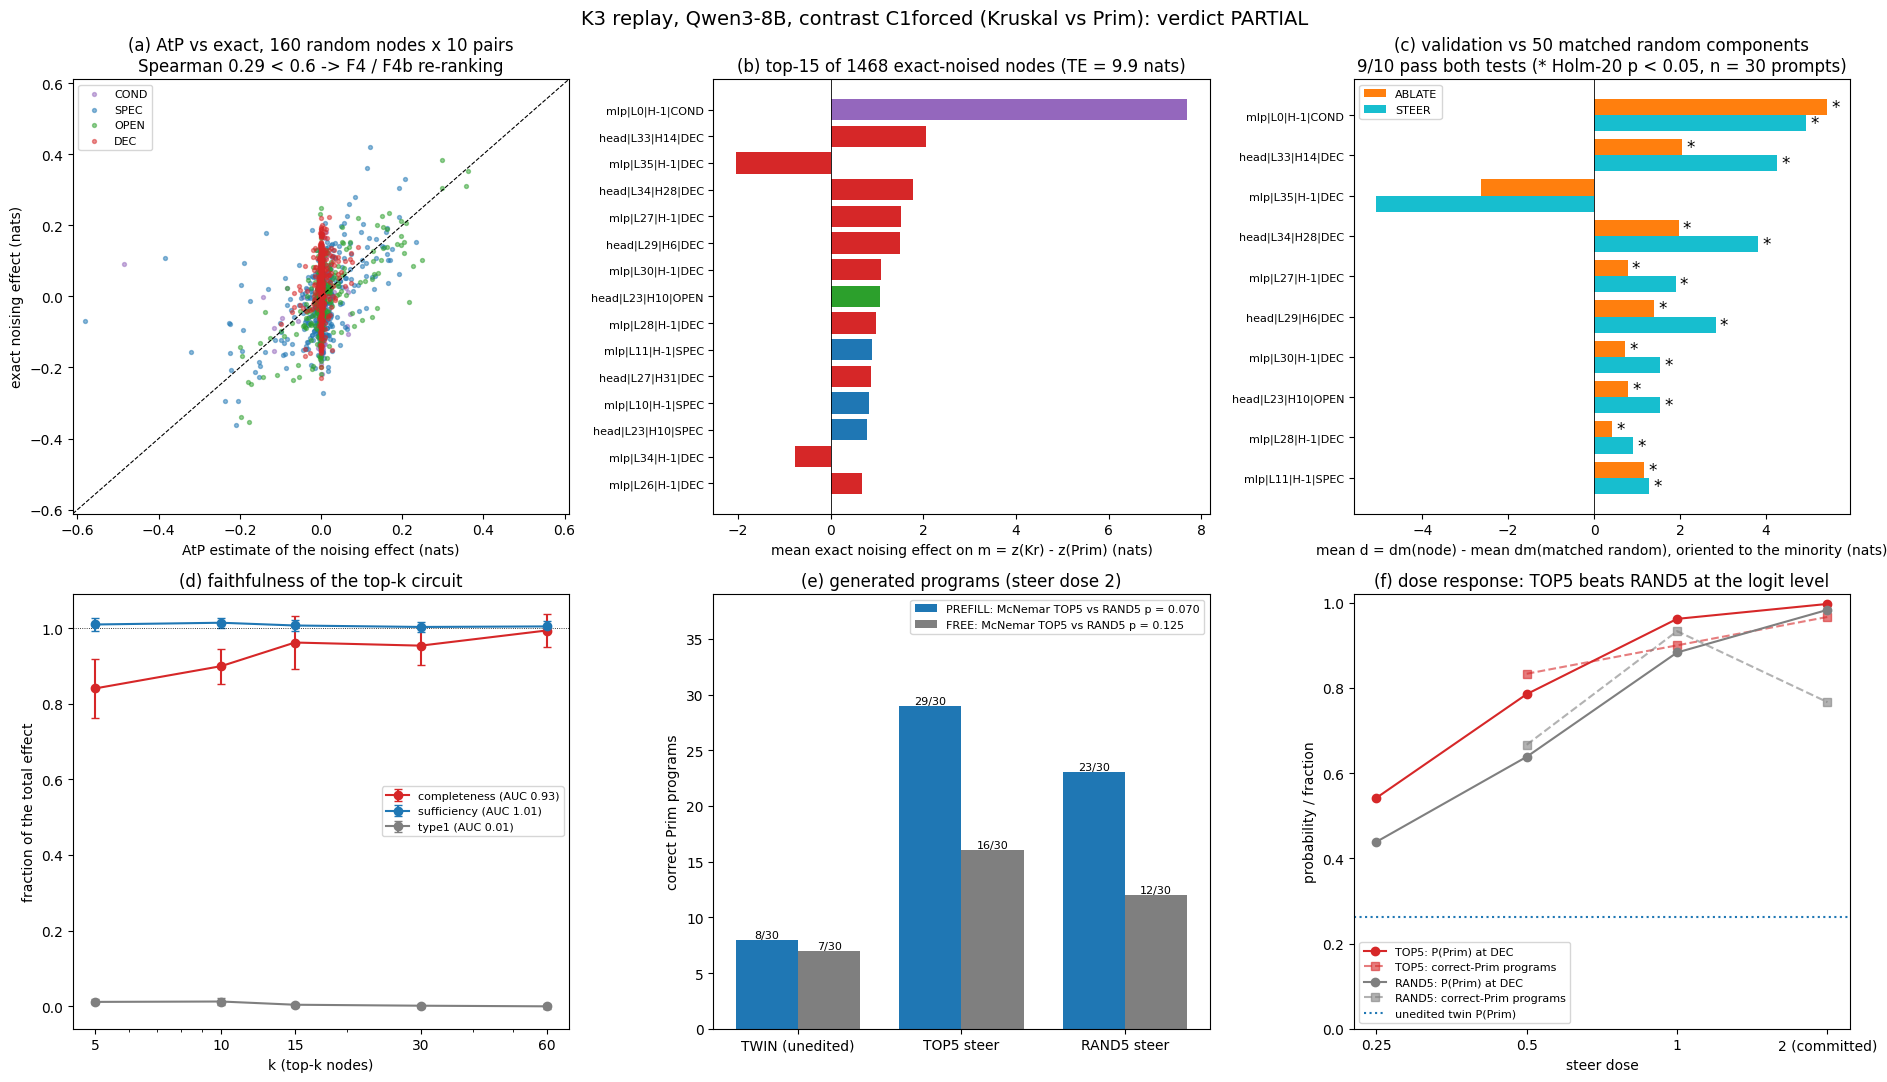

In [35]:
summary = pd.DataFrame([{"rank": i + 1, "node": k_, "class": k_.split("|")[3],
                         "exact noising effect (nats)": float(pool[KC.KEY2IDX[k_]].mean()),
                         "ablate mean d": a["mean_d"], "ablate p": a["p_holm_20"],
                         "steer mean d": s_["mean_d"], "steer p": s_["p_holm_20"], "pass both": p["both"]}
                        for i, (k_, a, s_, p) in enumerate(zip(res["top10"], val["per_node"]["ablate"],
                                                               val["per_node"]["steer"], val["node_pass"]))])
display(summary.round(4))
print(f"K3 verdict ({NAME}): {K3['C1_primary']['verdict']}")

CLS_C = {"COND": "tab:purple", "SPEC": "tab:blue", "OPEN": "tab:green", "DEC": "tab:red"}
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
# (a) AtP vs exact noising on the 160 random reliability nodes, per pair
ax = axes[0, 0]
xa, ya = atp[:, rel_nodes].ravel(), rel_noise.ravel()
cl = np.repeat([[k_.split("|")[3] for k_ in [KC.node_key(KC.NODES[j]) for j in rel_nodes]]], len(pairs), 0).ravel()
for c_, col in CLS_C.items():
    ax.scatter(xa[cl == c_], ya[cl == c_], s=8, alpha=0.5, color=col, label=c_)
lim = float(max(np.abs(xa).max(), np.abs(ya).max())) * 1.05
ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="AtP estimate of the noising effect (nats)",
       ylabel="exact noising effect (nats)",
       title=f"(a) AtP vs exact, 160 random nodes x {len(pairs)} pairs\n"
             f"Spearman {res['atp_vs_exact_random160']['spearman']:.2f} < 0.6 -> F4 / F4b re-ranking")
ax.legend(fontsize=8)
# (b) top-15 nodes by |mean exact noising effect| after F4b
ax = axes[0, 1]
t15 = res["top15"]
ax.barh(range(15), [pool[KC.KEY2IDX[k_]].mean() for k_ in t15], color=[CLS_C[k_.split("|")[3]] for k_ in t15])
ax.set_yticks(range(15), t15, fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.6)
ax.set(xlabel="mean exact noising effect on m = z(Kr) - z(Prim) (nats)",
       title=f"(b) top-15 of {res['n_exact_noised_total']} exact-noised nodes (TE = {res['TE_mean']:.1f} nats)")
# (c) validation: mean d (node minus mean of its matched random components) per test
ax = axes[0, 2]
yy = np.arange(10)
for off, mode, col in ((-0.2, "ablate", "tab:orange"), (0.2, "steer", "tab:cyan")):
    recs = val["per_node"][mode]
    ax.barh(yy + off, [r["mean_d"] for r in recs], height=0.4, color=col, label=mode.upper())
    for y_, r in zip(yy, recs):
        if r["p_holm_20"] < 0.05:
            ax.text(max(r["mean_d"], 0) + 0.1, y_ + off, "*", va="center", fontsize=12)
ax.set_yticks(yy, res["top10"], fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.6)
ax.legend(fontsize=8)
ax.set(xlabel="mean d = dm(node) - mean dm(matched random), oriented to the minority (nats)",
       title=f"(c) validation vs {N_RAND} matched random components\n"
             f"{val['n_pass_both_holm20']}/10 pass both tests (* Holm-20 p < 0.05, n = {val['n_prompts']} prompts)")
# (d) faithfulness curves
ax = axes[1, 0]
fk = res["faithfulness"]
for key, col in (("completeness", "tab:red"), ("sufficiency", "tab:blue"), ("type1", "tab:gray")):
    if f"{key}_mean" in fk:
        ax.errorbar(fk["k"], fk[f"{key}_mean"], yerr=fk[f"{key}_sd"], marker="o", capsize=3, color=col,
                    label=f"{key} (AUC {fk[f'{key}_auc_logk']:.2f})")
ax.set_xscale("log")
ax.set_xticks(fk["k"], [str(k_) for k_ in fk["k"]])
ax.axhline(1, color="k", lw=0.6, ls=":")
ax.set(xlabel="k (top-k nodes)", ylabel="fraction of the total effect", title="(d) faithfulness of the top-k circuit")
ax.legend(fontsize=8)
# (e) generation: correct-Prim programs per arm
ax = axes[1, 1]
arms = ("TWIN", "TOP5", "RAND5")
for i_, (cond, col) in enumerate((("PREFILL", "tab:blue"), ("FREE", "tab:gray"))):
    if cond not in gen:
        continue
    v_ = [gen[cond]["arms"][a_]["correct_target"] for a_ in arms]
    n_ = gen[cond]["arms"]["TWIN"]["n"]
    b_ = ax.bar(np.arange(3) + (i_ - 0.5) * 0.38, v_, width=0.38, color=col,
                label=f"{cond}: McNemar TOP5 vs RAND5 p = {gen[cond]['TOP5_vs_RAND5']['mcnemar_p_two_sided']:.3f}")
    ax.bar_label(b_, [f"{x}/{n_}" for x in v_], fontsize=8)
ax.set_xticks(range(3), ["TWIN (unedited)", "TOP5 steer", "RAND5 steer"])
ax.set(ylabel="correct Prim programs", ylim=(0, gen["PREFILL"]["arms"]["TWIN"]["n"] * 1.3),
       title="(e) generated programs (steer dose 2)")
ax.legend(fontsize=8)
# (f) dose response at the decision token (logit level) + generation outcomes
ax = axes[1, 2]
lp_ = dose["logit_p_minority_mean"]
for a_, col in (("TOP5", "tab:red"), ("RAND5", "tab:gray")):
    ds_ = sorted(lp_[a_], key=float)
    ax.plot([float(d) for d in ds_], [lp_[a_][d] for d in ds_], marker="o", color=col, label=f"{a_}: P(Prim) at DEC")
    gd = {float(d): v["TOP5_correct_target" if a_ == "TOP5" else "RAND5_correct_target"] / v["n"]
          for d, v in dose["doses"].items()}
    gd[2.0] = gen["PREFILL"]["arms"][a_]["correct_target"] / gen["PREFILL"]["arms"][a_]["n"]
    ax.plot(sorted(gd), [gd[d] for d in sorted(gd)], marker="s", ls="--", color=col, alpha=0.6,
            label=f"{a_}: correct-Prim programs")
ax.axhline(dose["logit_twin_p_minority_mean"], color="tab:blue", ls=":", label="unedited twin P(Prim)")
ax.set_xscale("log", base=2)
ax.set_xticks([0.25, 0.5, 1, 2], ["0.25", "0.5", "1", "2 (committed)"])
ax.set(xlabel="steer dose", ylabel="probability / fraction", ylim=(0, 1.02),
       title="(f) dose response: TOP5 beats RAND5 at the logit level")
ax.legend(fontsize=8)
fig.suptitle(f"K3 replay, Qwen3-8B, contrast {NAME} (Kruskal vs Prim): verdict {K3['C1_primary']['verdict']}",
             fontsize=14)
plt.tight_layout()
plt.show()

## What the replay shows (full-run config)

* **The decision is read out late, at the decision position.** On the pre-registered motif list (top 40 by |AtP| +
  20 calibration nodes), 62 % of the |exact noising effect| sits on DEC nodes: attention heads L33 H14, L34 H28 and
  L29 H6, and the late MLPs of layers 26-35 (effect-weighted depth 0.86). This differs from Gemma's G1 motif, where COND
  carries 36 %.
* **Attribution patching was not trustworthy here.** On random nodes, AtP and IG-AtP correlate with exact patching at
  Spearman 0.29 and 0.20. That triggered F4/F4b, and the final ranking uses exact noising of 1,468 nodes. The sweep
  found the single largest node, which AtP had missed: the layer-0 MLP at the forced instruction (COND), at
  7.7 of 9.9 nats.
* **Node-level causal tests pass.** 9 of the 10 frozen nodes beat their 50 write-norm-matched random components under
  both ABLATE and STEER (Holm over 20). The exception is `mlp|L35|DEC`, whose large effect points the other way.
* **Generation: strong but not specific enough.** Steering the top-5 makes 29/30 programs correct Prim implementations,
  against 8/30 unedited. The matched random five also reach 23/30, so TOP5 vs RAND5 is 7:1 discordant and the two-sided
  McNemar p = 0.07 misses 0.05. **K3 = PARTIAL**: the one-sided test, p = 0.035, would give PASS.
  The post-hoc dose curve shows why. At the committed dose 2, both arms push P(Prim) at the decision token to
  ≥ 0.98, because each random component is also steered along its *own* Prim-minus-Kruskal class-mean difference.
  At lower doses TOP5 stays ahead at the logit level (0.54 vs 0.44 at dose 0.25, 0.79 vs 0.64 at 0.5). In
  generation the two arms are level at dose 1 (27 vs 28 of 30).
* **Faithfulness.** Denoising only the top 5 nodes in the corrupt run already restores the clean metric (sufficiency
  ≈ 1, carried by the layer-0 COND MLP). Noising them removes most of it (completeness 0.84 at k = 5). But keeping
  only the top 60 live while every other node is frozen to its corrupt value recovers almost nothing (type 1 ≈ 0).
  The signal passes through many more components than the top 60 on its way to the decision.

For the creativity question: the model's "default algorithm" is decided at a few late components at one token
position, and steering there rewrites the whole program. Nudging that decision is easy. The identified circuit's
specific advantage over matched late components shows mainly at low steering doses.

**Running the full pipeline** needs the artifact's repository, a ≥ 24 GB GPU, `Qwen/Qwen3-8B@b968826d` (~16 GB) and the
iteration-5/7 inputs. Run `uv run method.py --stages setup,contrasts,gputests,amend0a,circuit:C1forced,...` stage by
stage, as in the artifact's `run_chain*.sh`. Then run `analysis.py` for the summary, figures and `method_out.json`.